# CaloDiffusion: fidelity on the official `_2` evaluation files
**Continuation of Vishal's validation study — version 2.0, 17 November 2026.**

This notebook replaces the old reference caches with checksum-verified official evaluation files. It adapts your validation notebook at repository commit `1bf9faf58c133c2e38358fbf8e39f21a6021e967`. The pretrained weights are unchanged; no training occurs.

**First action:** preserve the earlier archives as training-exposed comparisons. Run this notebook as a new study. Do not combine the old and new reference samples. A successful fidelity run provides the baseline for later outlier and per-particle studies.

Select a GPU runtime in Colab, edit Section 1, and run in order. Default: **electron**, 300 reference events per energy window, three generation seeds, two repeats per seed (1,800 generated events per window). Change `PARTICLES` for photon/pion or all three. `smoke` is only an execution test. Generation uses the full original 398-update schedule in both modes.

The `_2` designation establishes the challenge's evaluation split; it does not alone prove that a particular released checkpoint was never selected/tuned against it. Record evidence below when available. This does not block running the new-reference study.

**Scope:** response, occupancy, longitudinal/radial shape, correlations, seed stability, and native-array exports. No post-hoc threshold tuning, automatic outlier deletion, classifier training, or fitted controls on `_2`. Later exploratory outlier findings must be labelled as such. Remaining rows are left unused for subsequent predeclared work; they are not made independent of checkpoint selection merely by reserving them.


## 1. Settings to choose before looking at results
Retain the original cuts for continuity: electron 15.1 keV; photon/pion 10 MeV. These are **analysis cuts**, not changes to model ECUT. Native values below model ECUT are treated as in your audited inverse; analysis thresholds are applied equally to reference and generated showers. The boundary convention is `energy >= cut` for both deposits and hit counts.

Drive persistence is enabled by default. Data downloads stay on the Colab disk; results and completed generation batches go to Drive. With Drive disabled, download the final ZIP before the session ends. A frozen run signature allows interrupted runs to reuse completed batches; changing settings, code, data, or environment creates a separate run. Do not change batch size midway and expect the same events.


In [ ]:
from pathlib import Path

# Choose which particle(s) to study.
PARTICLES = ("pion","electron")
# Alternatives: ("photon",), ("pion",), or ("electron", "photon", "pion")

PROFILE = "fidelity"  # "smoke" is for execution checks only

# Section 2 mounts Google Drive.
USE_GOOGLE_DRIVE = True

# Change this folder if you saved the datasets elsewhere.
DRIVE_DATA_DIR = Path("/content/drive/MyDrive/CaloDiffusion/Calodiffusion_new_reference/datasets")
LOCAL_DATA_DIR = DRIVE_DATA_DIR

# Use complete official files from Drive.
# Only files for the selected PARTICLES need to be present.
# Section 4 verifies their published checksums.
LOCAL_FILE_OVERRIDES = {
    "electron": str(DRIVE_DATA_DIR / "dataset_2_2.hdf5"),
    "photon": str(DRIVE_DATA_DIR / "dataset_1_photons_2.hdf5"),
    "pion": str(DRIVE_DATA_DIR / "dataset_1_pions_2.hdf5"),
}

# Keep the original study settings unchanged.
GENERATION_SEEDS = {
    "electron": [20261110, 20261111, 20261112],
    "photon": [20261020, 20261021, 20261022],
    "pion": [20260110, 20260111, 20260112],
}

PARTITION_SEED = 20261117
ANALYSIS_SEED = 20261118
BATCH_SIZE = 16

# Add supporting evidence if available; otherwise leave empty.
# Evaluation filenames alone do not establish checkpoint independence.
CHECKPOINT_INDEPENDENCE_EVIDENCE = ""

REPO_COMMIT = "1bf9faf58c133c2e38358fbf8e39f21a6021e967"
REPO_URL = "https://github.com/Vishal21501/gen-hep-notebooks.git"

## 2. Install missing packages and prepare persistent output
Keep Colab's PyTorch/CUDA installation. This cell installs only missing analysis packages. It requires a GPU for the full experiment and records the exact environment for replay.


In [ ]:
import os, sys, subprocess, importlib.util
required = {"numpy":"numpy", "pandas":"pandas", "scipy":"scipy", "h5py":"h5py",
            "yaml":"PyYAML", "sklearn":"scikit-learn", "matplotlib":"matplotlib",
            "requests":"requests", "tqdm":"tqdm", "einops":"einops"}
missing = [pkg for mod,pkg in required.items() if importlib.util.find_spec(mod) is None]
if missing: subprocess.check_call([sys.executable,"-m","pip","install","-q",*missing])
import io, json, hashlib, random, warnings, shutil, zipfile, gc
from contextlib import contextmanager, redirect_stdout
from dataclasses import dataclass, asdict
from types import SimpleNamespace
from datetime import datetime, timezone
from importlib import metadata
import xml.etree.ElementTree as ET
import numpy as np
import pandas as pd
import scipy
from scipy import stats
from scipy.special import expit
import h5py, torch, requests
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display
if not torch.cuda.is_available():
    raise RuntimeError("Select Runtime > Change runtime type > GPU, then restart and run again.")
if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    RESULTS_BASE = Path('/content/drive/MyDrive/CaloDiffusion_new_reference')
else:
    RESULTS_BASE = Path('/content/CaloDiffusion_new_reference')
RESULTS_BASE.mkdir(parents=True,exist_ok=True)
assert PROFILE in ('smoke','fidelity')
assert PARTICLES and len(set(PARTICLES)) == len(PARTICLES)
assert set(PARTICLES) <= {'electron','photon','pion'}
CFG = SimpleNamespace(sample_offset=2, batch_size=BATCH_SIZE,
    n_test=300 if PROFILE=='fidelity' else 16,
    n_pilot=32 if PROFILE=='fidelity' else 8,
    generation_repeats=2 if PROFILE=='fidelity' else 1,
    n_bootstrap=500 if PROFILE=='fidelity' else 30,
    numeric_atol=2e-6, numeric_rtol=2e-5,
    electron_windows=((8.,12.),(40.,60.),(80.,120.)),
    discrete_energies=(8.192,32.768,65.536),
    radial_unit_label='XML radial-length units', z_centers_by_particle={}, z_unit_label='not supplied')
SEEDS = {p:GENERATION_SEEDS[p] if PROFILE=='fidelity' else GENERATION_SEEDS[p][:1] for p in PARTICLES}
assert BATCH_SIZE > 0 and all(len(v)==len(set(v)) for v in SEEDS.values())
ANALYSIS_CUT_GEV = {'electron':1.51e-5,'photon':.01,'pion':.01}
print('Particles:',PARTICLES,'profile:',PROFILE,'settings:',vars(CFG))
print('GPU:',torch.cuda.get_device_name())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Particles: ('pion', 'electron') profile: fidelity settings: {'sample_offset': 2, 'batch_size': 16, 'n_test': 300, 'n_pilot': 32, 'generation_repeats': 2, 'n_bootstrap': 500, 'numeric_atol': 2e-06, 'numeric_rtol': 2e-05, 'electron_windows': ((8.0, 12.0), (40.0, 60.0), (80.0, 120.0)), 'discrete_energies': (8.192, 32.768, 65.536), 'radial_unit_label': 'XML radial-length units', 'z_centers_by_particle': {}, 'z_unit_label': 'not supplied'}
GPU: Tesla T4


## 3. Load the exact original code and checkpoints
A sparse checkout retrieves only the wrapper and paper code/weights, excluding old reference caches and old result ZIPs. Existing checkouts must match the pinned commit and have no tracked modifications. No silent update to `main` is allowed.


In [ ]:
REPO = Path('/content/calodiffusion_pinned_'+REPO_COMMIT[:10])
env = dict(os.environ,GIT_LFS_SKIP_SMUDGE='1')
if not (REPO/'.git').exists():
    REPO.mkdir(parents=True,exist_ok=True)
    subprocess.run(['git','init',str(REPO)],check=True,env=env)
    subprocess.run(['git','-C',str(REPO),'remote','add','origin',REPO_URL],check=True,env=env)
    subprocess.run(['git','-C',str(REPO),'sparse-checkout','init','--no-cone'],check=True,env=env)
    subprocess.run(['git','-C',str(REPO),'sparse-checkout','set','--no-cone',
                    '/capstone/calodiffusion/calodiff_probe.py',
                    '/capstone/calodiffusion/paper_code/'],check=True,env=env)
    subprocess.run(['git','-C',str(REPO),'fetch','--depth','1','origin',REPO_COMMIT],check=True,env=env)
    subprocess.run(['git','-C',str(REPO),'checkout','--detach','FETCH_HEAD'],check=True,env=env)
assert subprocess.check_output(['git','-C',str(REPO),'rev-parse','HEAD'],text=True).strip()==REPO_COMMIT
if subprocess.check_output(['git','-C',str(REPO),'status','--porcelain','--untracked-files=no'],text=True).strip():
    raise RuntimeError('Pinned source has tracked modifications; use a clean checkout.')
ROOT = REPO/'capstone/calodiffusion'
for p,filename in {'electron':'dataset2.pth','photon':'dataset1_photon.pth','pion':'dataset1_pion.pth'}.items():
    if p not in PARTICLES: continue
    path=ROOT/'paper_code/trained_models'/filename
    if not path.is_file() or path.stat().st_size < 1024:
        raise RuntimeError(f'Missing/full checkpoint unavailable: {path}. Resolve Git LFS before proceeding.')
os.environ['CALODIFF_DEVICE']='cuda'
sys.path.insert(0,str(ROOT))
import calodiff_probe as cp
assert Path(cp.__file__).resolve()==ROOT/'calodiff_probe.py', 'Restart runtime: wrong wrapper imported.'
try: get_ipython().run_line_magic('matplotlib','inline')
except (NameError,AttributeError): pass
torch.backends.cudnn.benchmark=False
torch.backends.cudnn.deterministic=True
torch.use_deterministic_algorithms(True,warn_only=True)
torch.backends.cuda.matmul.allow_tf32=False
torch.backends.cudnn.allow_tf32=False


## 4. Download and verify only the new evaluation files
Published MD5 checksums below were checked against the linked Zenodo records. Download to a `.part` file, verify, then rename. A matching basename alone is insufficient. Every local override undergoes the same check; the old 12,000-event caches cannot pass it. SHA-256 is recorded as the study identifier. Downloads can be skipped on later runs when the verified file is already present.

- [Electron Dataset 2](https://zenodo.org/records/6366271): `dataset_2_2.hdf5`
- [Photon/pion Dataset 1](https://zenodo.org/records/8099322): `dataset_1_photons_2.hdf5`, `dataset_1_pions_2.hdf5`


In [ ]:
DATASETS = {
 'electron':dict(record=6366271,filename='dataset_2_2.hdf5',md5='7a56fd68aa53ded37c2ac445694d9736',nvox=6480),
 'photon':dict(record=8099322,filename='dataset_1_photons_2.hdf5',md5='4767715ed56e99565fd9c67340661e70',nvox=368),
 'pion':dict(record=8099322,filename='dataset_1_pions_2.hdf5',md5='fee7457b40127bc23c8ab909e2638ca0',nvox=533)}
def digest_file(path, algorithm='sha256'):
    h=hashlib.new(algorithm)
    with Path(path).open('rb') as f:
        for b in iter(lambda:f.read(4*1024**2),b''): h.update(b)
    return h.hexdigest()
def obtain_dataset(particle):
    spec=DATASETS[particle]
    path=Path(LOCAL_FILE_OVERRIDES.get(particle,LOCAL_DATA_DIR/spec['filename']))
    if path.name != spec['filename']: raise ValueError('Use the exact official filename.')
    if not path.exists():
        if particle in LOCAL_FILE_OVERRIDES: raise FileNotFoundError(path)
        path.parent.mkdir(parents=True,exist_ok=True)
        url=f"https://zenodo.org/records/{spec['record']}/files/{spec['filename']}?download=1"
        partial=path.with_suffix(path.suffix+'.part')
        with requests.get(url,stream=True,timeout=(30,180)) as r:
            r.raise_for_status()
            with partial.open('wb') as f, tqdm(total=int(r.headers.get('Content-Length',0)),unit='B',unit_scale=True,desc=spec['filename']) as bar:
                for chunk in r.iter_content(4*1024**2):
                    if chunk: f.write(chunk);bar.update(len(chunk))
        if digest_file(partial,'md5') != spec['md5']:
            raise RuntimeError(f'Checksum failed: {partial}; no data will be analysed.')
        partial.replace(path)
    actual=digest_file(path,'md5')
    if actual != spec['md5']: raise RuntimeError(f'Wrong/corrupt reference {path}: {actual}')
    if not h5py.is_hdf5(path): raise ValueError('Verified input is not readable HDF5.')
    with h5py.File(path) as f:
        assert {'showers','incident_energies'} <= set(f)
        shape=f['showers'].shape
        assert len(shape)==2 and shape[1]==spec['nvox']
        assert f['incident_energies'].shape==(shape[0],1)
    return dict(path=str(path),sha256=digest_file(path),md5=actual,n_events=shape[0],
                n_voxels=shape[1],record=spec['record'],filename=spec['filename'],input_unit='MeV')
DATA_INFO={p:obtain_dataset(p) for p in PARTICLES}
display(pd.DataFrame(DATA_INFO).T)
# Redirect wrapper defaults too: no helper can silently fall back to a cache.
for p in PARTICLES: cp.PARTICLES[p]['data']=DATA_INFO[p]['path']


,path,sha256,md5,n_events,n_voxels,record,filename,input_unit
pion,/content/drive/MyDrive/CaloDiffusion/Calodiffu...,464c5138bbb3d4b22a6f6d25c2d06c76333f0153880c54...,fee7457b40127bc23c8ab909e2638ca0,120800,533,8099322,dataset_1_pions_2.hdf5,MeV
electron,/content/drive/MyDrive/CaloDiffusion/Calodiffu...,7561885bda9e2cfa2b0464d7ba779cd4066d89e91ce610...,7a56fd68aa53ded37c2ac445694d9736,100000,6480,6366271,dataset_2_2.hdf5,MeV


## 5. Freeze the run and record provenance
Run identity includes settings, reference/checkpoint/source hashes, helper-code revision, and software/GPU environment. Existing batches are accepted only inside the matching run. The reference is an official evaluation file; checkpoint-selection independence remains a separate, explicitly recorded question.


In [ ]:
def json_clean(x):
    if isinstance(x, dict): return {str(k): json_clean(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)): return [json_clean(v) for v in x]
    if isinstance(x, np.ndarray): return json_clean(x.tolist())
    if isinstance(x, np.generic): return json_clean(x.item())
    if isinstance(x, Path): return str(x)
    if isinstance(x, float) and not np.isfinite(x): return None
    return x

def save_json(path, obj):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(json_clean(obj), indent=2, allow_nan=False))

def capture_rng():
    return dict(cpu=torch.random.get_rng_state().clone(),
                cuda=[s.clone() for s in torch.cuda.get_rng_state_all()] if torch.cuda.is_available() else [],
                numpy=np.random.get_state(), python=random.getstate())

def restore_rng(s):
    torch.random.set_rng_state(s['cpu'])
    if s['cuda']: torch.cuda.set_rng_state_all(s['cuda'])
    np.random.set_state(s['numpy']); random.setstate(s['python'])

@contextmanager
def rng_context(seed=None, state=None):
    if (seed is None) == (state is None):
        raise ValueError("Supply exactly one of seed or state.")
    old = capture_rng()
    try:
        if state is not None:
            restore_rng(state)
        else:
            torch.manual_seed(int(seed)); np.random.seed(int(seed) % 2**32); random.seed(int(seed))
            if torch.cuda.is_available(): torch.cuda.manual_seed_all(int(seed))
        yield
    finally:
        restore_rng(old)

@contextmanager
def quiet_legacy():
    # Suppress the legacy per-decode 'dset ...' print, not numerical warnings or exceptions.
    with redirect_stdout(io.StringIO()): yield

def gate(name, ok, **details):
    row = dict(check=name, passed=bool(ok), **json_clean(details)); GATES.append(row)
    save_json(OUT / 'validation_gates.json', GATES)
    if not ok: raise AssertionError(f"Validation failed: {name}. Details: {details}")


In [ ]:
def stable_seed(*parts):
    return int(hashlib.sha256('|'.join(map(str,parts)).encode()).hexdigest()[:8],16)
def named_seed(*parts): return stable_seed(ANALYSIS_SEED,*parts)
CHECKPOINTS={p:dict(path=str(ROOT/'paper_code/trained_models'/cp.PARTICLES[p]['ckpt']),
    sha256=digest_file(ROOT/'paper_code/trained_models'/cp.PARTICLES[p]['ckpt'])) for p in PARTICLES}
source_files=[ROOT/'calodiff_probe.py',*sorted((ROOT/'paper_code').rglob('*.py')),
              *sorted((ROOT/'paper_code').rglob('*.json')),*sorted((ROOT/'paper_code').rglob('*.xml'))]
ENVIRONMENT=dict(python=sys.version,packages={k:metadata.version(k) for k in
    ['torch','numpy','scipy','pandas','h5py','PyYAML','scikit-learn','matplotlib']},
    cuda=torch.version.cuda,cudnn=torch.backends.cudnn.version(),gpu=torch.cuda.get_device_name())
PLAN=dict(version='2.0',helper_revision='05ba0cf480bbc4a58cf67b93ffe90d00489718810fd7c525616fd4d28c88d77b',repo_commit=REPO_COMMIT,profile=PROFILE,
    particles=PARTICLES,config=vars(CFG),seeds=SEEDS,partition_seed=PARTITION_SEED,
    analysis_seed=ANALYSIS_SEED,analysis_cuts_GeV=ANALYSIS_CUT_GEV,
    reference_hashes={p:DATA_INFO[p]['sha256'] for p in PARTICLES},
    checkpoint_hashes={p:CHECKPOINTS[p]['sha256'] for p in PARTICLES},
    source_hashes={str(f.relative_to(ROOT)):digest_file(f) for f in source_files},environment=ENVIRONMENT)
RUN_ID='eval2_'+hashlib.sha256(json.dumps(json_clean(PLAN),sort_keys=True).encode()).hexdigest()[:16]
OUT=RESULTS_BASE/RUN_ID
for sub in ['tables','arrays','batches','figures','official_exports']: (OUT/sub).mkdir(parents=True,exist_ok=True)
plan_path=OUT/'frozen_plan.json'
if plan_path.exists():
    assert json.loads(plan_path.read_text())==json_clean(PLAN), 'Run signature collision or changed plan.'
else: save_json(plan_path,PLAN)
MANIFEST=dict(run_id=RUN_ID,plan=PLAN,references=DATA_INFO,checkpoints=CHECKPOINTS,
    reference_provenance='Official Zenodo evaluation _2 files, published MD5 verified',
    checkpoint_selection_independence='not inferred from evaluation filenames',
    checkpoint_independence_evidence=CHECKPOINT_INDEPENDENCE_EVIDENCE,
    created_or_resumed_utc=datetime.now(timezone.utc).isoformat())
save_json(OUT/'manifest.json',MANIFEST)
(OUT/'pip_freeze.txt').write_text(subprocess.check_output([sys.executable,'-m','pip','freeze'],text=True))
GATES=[]
print('Run:',RUN_ID,'Output:',OUT)
print('Do not relabel this as checkpoint-unseen without supporting training/selection evidence.')


Run: eval2_e270d961f41a6597 Output: /content/drive/MyDrive/CaloDiffusion_new_reference/eval2_e270d961f41a6597
Do not relabel this as checkpoint-unseen without supporting training/selection evidence.


## 6. Select fixed pilot and fidelity samples
Only incident energies are scanned in full. Within each energy stratum, a stable seed selects disjoint pilot and fidelity rows. The same fidelity rows and incident energies are used for **every generation seed**. Pilot events are for technical audits only. Remaining indices are exported as an unused reserve. This notebook does not fit calibration controls on any `_2` rows.

Electron windows: 8–12, 40–60, 80–120 GeV. Photon/pion energies: 8.192, 32.768, 65.536 GeV. Generation uses each selected reference event's actual energy, including inside electron windows. Matching an energy does not make the generated shower an event-by-event reconstruction.


In [ ]:
@dataclass
class ReferenceData:
    path: Path
    energy: np.ndarray
    fingerprint: str
    n_voxels: int
@dataclass
class EventBatch:
    native: np.ndarray
    energy: np.ndarray
    ids: np.ndarray
REFERENCES={}; STRATA={}; PARTITION_HASHES={}
for p in PARTICLES:
    info=DATA_INFO[p]
    with h5py.File(info['path']) as f: energy=np.asarray(f['incident_energies'][:],dtype=float).ravel()*1e-3
    gate(f'{p}: finite positive incident energies',np.all(np.isfinite(energy)&(energy>0)))
    config=cp._cfg(p)
    gate(f'{p}: model energy support',energy.min()>=config['EMIN']*(1-1e-5) and energy.max()<=config['EMAX']*(1+1e-5))
    REFERENCES[p]=ReferenceData(Path(info['path']),energy,info['sha256'],info['n_voxels'])
    if p=='electron':
        choices=[(f'{lo:g}-{hi:g}GeV',np.sqrt(lo*hi),np.flatnonzero((energy>=lo)&(energy<hi))) for lo,hi in CFG.electron_windows]
    else:
        choices=[(f'{e:g}GeV',e,np.flatnonzero(np.isclose(energy,e,rtol=2e-5,atol=1e-7))) for e in CFG.discrete_energies]
    rows=[]; STRATA[p]=[]; used=set()
    for label,nominal,idx in choices:
        assert not used.intersection(idx.tolist());used.update(idx.tolist())
        if len(idx)<CFG.n_pilot+CFG.n_test: raise ValueError(f'Insufficient events: {p}/{label}')
        rng=np.random.default_rng(stable_seed(PARTITION_SEED,info['sha256'],p,label))
        order=rng.permutation(idx)
        parts=dict(pilot=order[:CFG.n_pilot],test=order[CFG.n_pilot:CFG.n_pilot+CFG.n_test],
                   reserve=order[CFG.n_pilot+CFG.n_test:])
        STRATA[p].append(SimpleNamespace(label=label,nominal=nominal,partitions=parts))
        for split,indices in parts.items():
            rows.extend(dict(particle=p,stratum=label,partition=split,row=int(i),energy_GeV=energy[i],
                             event_id=f'{info["sha256"]}:{i}') for i in indices)
    path=OUT/'tables'/f'{p}_event_partitions.csv'
    pd.DataFrame(rows).to_csv(path,index=False);PARTITION_HASHES[p]=digest_file(path)
    print(p,pd.DataFrame(rows).groupby(['stratum','partition']).size().to_dict())
MANIFEST['partition_sha256']=PARTITION_HASHES
save_json(OUT/'manifest.json',MANIFEST)
INPUT_TO_GEV=1e-3


pion {('32.768GeV', 'pilot'): 32, ('32.768GeV', 'reserve'): 9668, ('32.768GeV', 'test'): 300, ('65.536GeV', 'pilot'): 32, ('65.536GeV', 'reserve'): 9668, ('65.536GeV', 'test'): 300, ('8.192GeV', 'pilot'): 32, ('8.192GeV', 'reserve'): 9668, ('8.192GeV', 'test'): 300}
electron {('40-60GeV', 'pilot'): 32, ('40-60GeV', 'reserve'): 5452, ('40-60GeV', 'test'): 300, ('8-12GeV', 'pilot'): 32, ('8-12GeV', 'reserve'): 5570, ('8-12GeV', 'test'): 300, ('80-120GeV', 'pilot'): 32, ('80-120GeV', 'reserve'): 5640, ('80-120GeV', 'test'): 300}


In [ ]:
def read_events(ref: ReferenceData, indices) -> EventBatch:
    idx = np.asarray(indices, dtype=np.int64)
    if idx.ndim != 1 or len(idx) == 0 or len(np.unique(idx)) != len(idx):
        raise ValueError('Provide a nonempty list of unique event indices.')
    order = np.argsort(idx)
    with h5py.File(ref.path, 'r') as f:
        raw = np.asarray(f['showers'][idx[order]], dtype=np.float64)
    raw = raw[np.argsort(order)].reshape(len(idx), -1) * INPUT_TO_GEV
    if not np.isfinite(raw).all() or (raw < 0).any():
        raise ValueError('Nonfinite or negative reference deposits; inspect data rather than silently clipping.')
    return EventBatch(raw, ref.energy[idx].copy(),
                      np.array([f'{ref.fingerprint}:{i}' for i in idx]))


## 7. Native geometry and observables
Reuse XML-derived native cell ordering from your validation code. Longitudinal depth is an **active-layer ordinal**, not an invented distance. Radius uses the XML bin centres. Empty showers retain response/occupancy zero and undefined shape values; their rate is reported separately. No empty event is silently removed from response comparisons.


In [ ]:
@dataclass
class NativeGeometry:
    particle: str
    layer_ids: np.ndarray
    layer_slices: list
    n_angles: list
    radial_edges: list
    layer_ordinal: np.ndarray
    radius: np.ndarray
    angle: np.ndarray
    physical_z: np.ndarray | None = None

    @property
    def n_voxels(self): return len(self.radius)
    @property
    def n_layers(self): return len(self.layer_ids)

def load_geometry(particle, root=ROOT) -> NativeGeometry:
    filename = {'electron':'binning_dataset_2.xml', 'photon':'binning_dataset_1_photons.xml',
                'pion':'binning_dataset_1_pions.xml'}[particle]
    path = Path(root)/'paper_code'/'CaloChallenge'/'code'/filename
    element = next((el for el in ET.parse(path).getroot() if el.attrib.get('name') == particle), None)
    if element is None: raise ValueError(f'{particle} not found in {path}')
    ids, slices, counts, edges, ordinals, radii, angles = [], [], [], [], [], [], []
    offset = 0
    for layer in element:
        r = np.fromstring(layer.attrib['r_edges'], sep=',')
        na = int(layer.attrib['n_bin_alpha'])
        if len(r) < 2: continue
        if not np.all(np.diff(r) > 0) or na < 1: raise ValueError('Invalid native binning.')
        nr = len(r)-1; nv = na*nr; ordinal = len(ids)
        ids.append(int(layer.attrib['id'])); slices.append(slice(offset,offset+nv)); offset += nv
        counts.append(na); edges.append(r)
        ordinals.extend([ordinal]*nv)
        radii.extend(np.tile(0.5*(r[:-1]+r[1:]), na))
        angles.extend(np.repeat(-np.pi + (np.arange(na)+0.5)*2*np.pi/na, nr))
    z = None
    if particle in CFG.z_centers_by_particle:
        centers = np.asarray(CFG.z_centers_by_particle[particle], dtype=float)
        if centers.shape != (len(ids),) or not np.isfinite(centers).all():
            raise ValueError('Supply one finite physical z center for each active layer.')
        z = centers[np.asarray(ordinals,dtype=int)]
    return NativeGeometry(particle,np.array(ids),slices,counts,edges,np.array(ordinals),
                          np.array(radii),np.array(angles),z)

def threshold_native(native, ecut):
    a = np.asarray(native, dtype=np.float64)
    if a.ndim != 2 or not np.isfinite(a).all(): raise ValueError('Expected a finite (events, native voxels) array.')
    # Negative inverse-logit excursions lie below a positive physical threshold, just as upstream.
    if ecut <= 0: raise ValueError('This study requires an explicit positive native-cell threshold.')
    return np.where(a < ecut, 0.0, a)

def native_observables(native, energy, geom: NativeGeometry, ecut) -> pd.DataFrame:
    ecut = ANALYSIS_CUT_GEV.get(geom.particle, ecut)
    a = threshold_native(native, ecut)
    E = np.asarray(energy,dtype=float).reshape(-1)
    if a.shape != (len(E),geom.n_voxels) or np.any(E <= 0): raise ValueError('Energy/geometry shape mismatch.')
    total = a.sum(axis=1); valid = total > 0
    inv = np.divide(1.,total,out=np.full_like(total,np.nan),where=valid)
    mean_r = (a @ geom.radius)*inv
    second_r = (a @ (geom.radius**2))*inv
    d = dict(energy_GeV=E, deposited_GeV=total, response=total/E,
        nhits=(a >= ecut).sum(axis=1), occupancy=(a >= ecut).mean(axis=1),
        empty=(~valid).astype(int), depth_layer=(a @ geom.layer_ordinal)*inv,
        r_mean=mean_r, r_rms=np.sqrt(np.maximum(second_r,0)),
        r_sigma=np.sqrt(np.maximum(second_r-mean_r**2,0)),
        x_centroid=(a @ (geom.radius*np.cos(geom.angle)))*inv,
        y_centroid=(a @ (geom.radius*np.sin(geom.angle)))*inv)
    layer_energy = np.stack([a[:,sl].sum(axis=1) for sl in geom.layer_slices],axis=1)
    for j in range(geom.n_layers):
        d[f'layer_fraction_{j}'] = layer_energy[:,j]*inv
    if geom.physical_z is not None: d['depth_physical'] = (a @ geom.physical_z)*inv
    # Follow the primer: spectral diagnostics only for the regular electron geometry.
    if geom.particle == 'electron':
        na = geom.n_angles[0]; nr = len(geom.radial_edges[0])-1
        phi = a.reshape(len(a),geom.n_layers,na,nr).sum(axis=(1,3))
        coeff = np.fft.rfft(phi,axis=1)
        for m in (1,4): d[f'angular_m{m}'] = np.abs(coeff[:,m])*inv
    return pd.DataFrame(d)
GEOMETRY={p:load_geometry(p) for p in PARTICLES}
for p,g in GEOMETRY.items():
    gate(f'{p}: XML voxel count',g.n_voxels==REFERENCES[p].n_voxels)
    save_json(OUT/f'{p}_geometry.json',dict(layer_ids=g.layer_ids,n_angles=g.n_angles,
        radial_edges=g.radial_edges,layer_ordinal=g.layer_ordinal,radius=g.radius,
        angle=g.angle,radial_unit=CFG.radial_unit_label,flattening='layer, angle, radius'))
OBSERVABLES=['deposited_GeV','response','occupancy','empty','depth_layer','r_rms','r_sigma']
LABELS=dict(deposited_GeV='Deposited energy (GeV)',response='E_dep / E_inc',
    occupancy='Native-cell occupancy',empty='Empty-shower indicator',
    depth_layer='Mean active-layer ordinal',r_rms='RMS radius (XML units)',r_sigma='Radial width (XML units)')


## 8. Validate transformations and the unchanged sampler
The following functions are adapted from your validation notebook. Checks include energy encoding, forward noise, preprocessing round trip, stable versus legacy inverse, energy-conserving rebinning, repeatability, tracing neutrality, and unchanged replay. A failed gate stops execution. These are numerical correctness checks, not a declaration of physics fidelity. A small number of pilot events cannot certify every possible input.

No model ECUT, weight, or diffusion-schedule parameter is retuned. The configured `sample_offset=2` is retained.


In [ ]:
MODELS={}
def get_model(particle):
    # Cache at most one real model at a time. All results below live on CPU/disk.
    if particle not in MODELS:
        MODELS.clear()
        if torch.cuda.is_available(): torch.cuda.empty_cache()
        with quiet_legacy(): model = cp.load_model(particle)
        if model.config['SHOWERMAP'] != 'logit-norm' or not model.config['logE']:
            raise NotImplementedError('This audited adapter supports the supplied logit-norm/logE checkpoints only.')
        if model.training_obj != 'noise_pred' or not model.discrete_time or model.cold_diffu:
            raise NotImplementedError('This notebook targets the supplied discrete, noise-prediction, non-cold checkpoints.')
        model.eval()
        for parameter in model.parameters(): parameter.requires_grad_(False)
        MODELS[particle] = model
    return MODELS[particle]

def encode_native(model, native, energy):
    cfg = model.config
    native = np.asarray(native,dtype=np.float32).reshape(len(energy),-1)
    e = np.asarray(energy,dtype=np.float32).reshape(-1,1)
    f = native/(float(cfg['MAXDEP'])*e)
    if not np.isfinite(f).all() or (f < 0).any() or (f >= 1).any():
        raise ValueError('Reference voxel outside the valid logit domain. Investigate rather than masking it.')
    with quiet_legacy():
        encoded = cp.utils.preprocess_shower(native.copy(),e,shape=cfg['SHAPE_PAD'],
            showerMap=cfg['SHOWERMAP'],dataset_num=cfg['DATASET_NUM'],
            orig_shape=model._orig_shape,ecut=cfg['ECUT'],max_deposit=cfg['MAXDEP'])
    x = torch.as_tensor(encoded,dtype=torch.float32,device=cp.DEVICE)
    return x.reshape(len(e),*model._data_shape)

def decode_native(model, x, energy, *, apply_cut=True):
    arr = x.detach().cpu().numpy() if torch.is_tensor(x) else np.asarray(x)
    arr = np.asarray(arr,dtype=np.float64).reshape(len(energy),-1)
    if not np.isfinite(arr).all(): raise ValueError('Nonfinite model-space sample: do not hide a sampler failure.')
    cfg = model.config
    dataset_key = cfg['DATASET_NUM'] + (10 if model._orig_shape and cfg['DATASET_NUM'] <= 1 else 0)
    params = cp.utils.dataset_params[dataset_key]
    logits = arr*params['logit_std'] + params['logit_mean']
    fractions = (expit(logits)-1e-6)/(1-2e-6)
    native = fractions * float(cfg['MAXDEP']) * np.asarray(energy,dtype=float).reshape(-1,1)
    if native.shape[1] != int(cfg['SHAPE_ORIG'][-1]):
        raise ValueError('Unexpected model/native dimensions; unsupported geometry path.')
    return threshold_native(native,cfg['ECUT']) if apply_cut else native

def physical_regular_grid(model, native):
    native = np.asarray(native,dtype=np.float32)
    if model.NN_embed is None:
        return native.reshape(len(native),*model.config['SHAPE_PAD'][2:])
    gc = model.NN_embed.gc
    return gc.convert(gc.reshape(torch.from_numpy(native))).detach().cpu().numpy()

def audit_transforms(particle):
    model = get_model(particle); geom = GEOMETRY[particle]
    indices = np.concatenate([s.partitions['pilot'][:4] for s in STRATA[particle]])
    batch = read_events(REFERENCES[particle],indices)
    encoded_energy=cp.encode_energy(particle,batch.energy).detach().cpu().numpy()
    restored_energy=cp._e_to_gev(encoded_energy,model.config)
    gate(f'{particle}: energy-condition round trip',np.allclose(restored_energy,batch.energy,rtol=2e-6,atol=1e-7))
    x = encode_native(model,batch.native,batch.energy)
    with rng_context(seed=named_seed('forward_noise_audit',particle)):
        eps=torch.randn_like(x); ti=cp.NSTEPS//2
        xt,_=cp.noise_at(model,x,t=ti,noise=eps)
        # These are the supplied schedule coefficients, not a new schedule.
        expected_xt=model.sqrt_alphas_cumprod[ti]*x+model.sqrt_one_minus_alphas_cumprod[ti]*eps
        gate(f'{particle}: forward-noise formula',torch.allclose(xt,expected_xt,rtol=1e-6,atol=1e-7))
    stable = decode_native(model,x,batch.energy)
    expected = threshold_native(batch.native,model.config['ECUT'])
    rel_l1 = np.abs(stable-expected).sum(axis=1)/np.maximum(expected.sum(axis=1),1e-12)
    gate(f'{particle}: preprocessing round trip',np.all(rel_l1 < 5e-4), max_relative_L1=float(rel_l1.max()))
    with quiet_legacy():
        legacy = np.asarray(cp.to_physical(model,x,batch.energy)).reshape(len(batch.energy),-1)
    delta = np.abs(stable-legacy).sum(axis=1)/np.maximum(expected.sum(axis=1),1e-12)
    gate(f'{particle}: stable/legacy inverse agreement',np.isfinite(legacy).all() and np.all(delta < 5e-4),
         max_relative_L1=float(delta.max()))
    grid = physical_regular_grid(model,stable)
    grid_sum = grid.reshape(len(grid),-1).sum(axis=1,dtype=np.float64)
    gate(f'{particle}: rebinning energy conservation',
         np.allclose(grid_sum,stable.sum(axis=1),rtol=2e-5,atol=1e-8))
    native_obs = native_observables(stable,batch.energy,geom,model.config['ECUT'])
    audit = pd.DataFrame(dict(event_id=batch.ids,roundtrip_relative_L1=rel_l1,
        decoder_relative_L1=delta, raw_deposited_GeV=batch.native.sum(axis=1),
        thresholded_deposited_GeV=stable.sum(axis=1),native_hits=native_obs['nhits'],
        regular_grid_hits=(grid.reshape(len(grid),-1)>model.config['ECUT']).sum(axis=1)))
    audit.to_csv(OUT/'tables'/f'{particle}_transform_audit.csv',index=False)
    return audit


In [ ]:
@dataclass
class Snapshot:
    x: torch.Tensor  # CPU tensor
    next_t: int
    completed_updates: int
    rng: dict

@dataclass
class TraceResult:
    final: np.ndarray
    times: np.ndarray
    observables: pd.DataFrame
    snapshots: dict
    features: np.ndarray | None = None

def standard_generate(model, energy, seed):
    E = cp.encode_energy(model._particle,np.asarray(energy,dtype=float))
    with rng_context(seed=seed), torch.inference_mode(), quiet_legacy():
        result = cp.sample(model,E,num_steps=cp.NSTEPS,sample_offset=CFG.sample_offset,debug=False)
    a = result.detach().cpu().numpy() if torch.is_tensor(result) else np.asarray(result)
    if not np.isfinite(a).all(): raise ValueError('Nonfinite standard sample.')
    return a

def traced_generate(model, energy, seed, snapshot_counts=(), capture_features=False):
    energy = np.asarray(energy,dtype=float); particle=model._particle
    E = cp.encode_energy(particle,energy); total_steps=cp.NSTEPS-CFG.sample_offset
    counts = set(int(v) for v in snapshot_counts)
    if any(v<0 or v>total_steps for v in counts): raise ValueError('Snapshot count outside sampling schedule.')
    original = model.p_sample; had_instance_method = 'p_sample' in model.__dict__
    previous = model.__dict__.get('p_sample')
    snapshots, records, times, features = {}, [], [], []
    handle = None
    if capture_features:
        def feature_hook(module, inputs, output):
            features.append(output.detach().mean(dim=tuple(range(2,output.ndim))).cpu().numpy())
        handle = model.model.mid_block2.register_forward_hook(feature_hook)

    def wrapped(x, E_arg, t, *args, **kwargs):
        if args: raise RuntimeError('Unexpected positional p_sample extras; audit upstream API.')
        ti = int(t[0].item()); completed=len(times)
        if not torch.all(t == ti): raise ValueError('Mixed-timestep sampler call unsupported.')
        expected = total_steps-1-completed
        if ti != expected: raise RuntimeError(f'Unexpected schedule: got {ti}, expected {expected}.')
        if completed == 0 and 0 in counts:
            snapshots[0] = Snapshot(x.detach().cpu().clone(),ti,0,capture_rng())
        wants_debug=bool(kwargs.get('debug',False)); kwargs['debug']=True
        xprev,xhat0 = original(x,E_arg,t,**kwargs)
        completed += 1; times.append(ti)
        if completed in counts:
            snapshots[completed] = Snapshot(xprev.detach().cpu().clone(),ti-1,completed,capture_rng())
        native = decode_native(model,xhat0,energy)
        obs = native_observables(native,energy,GEOMETRY[particle],model.config['ECUT'])
        obs['frame'] = completed-1; obs['timestep']=ti
        obs['completed_updates']=completed; obs['event_in_batch']=np.arange(len(energy))
        records.append(obs)
        return (xprev,xhat0) if wants_debug else xprev

    model.p_sample = wrapped
    try:
        with rng_context(seed=seed), torch.inference_mode(), quiet_legacy():
            result = cp.sample(model,E,num_steps=cp.NSTEPS,sample_offset=CFG.sample_offset,debug=False)
    finally:
        if had_instance_method: model.p_sample=previous
        else: delattr(model,'p_sample')
        if handle is not None: handle.remove()
    final = result.detach().cpu().numpy() if torch.is_tensor(result) else np.asarray(result)
    if len(times)!=total_steps: raise RuntimeError('Wrong number of sampler updates.')
    feat = np.stack(features) if capture_features else None
    if feat is not None and feat.shape[0]!=len(times): raise RuntimeError('Hook/step alignment failed.')
    return TraceResult(final,np.array(times),pd.concat(records,ignore_index=True),snapshots,feat)

def resume_native(model, snapshot: Snapshot, energy, *, fresh_seed=None):
    E = cp.encode_energy(model._particle,np.asarray(energy,dtype=float))
    device=next(model.parameters()).device; dtype=next(model.parameters()).dtype
    x=snapshot.x.to(device=device,dtype=dtype).clone()
    if x.shape[0]!=len(E): raise ValueError('Snapshot/energy batch size mismatch.')
    context = rng_context(state=snapshot.rng) if fresh_seed is None else rng_context(seed=fresh_seed)
    with context, torch.inference_mode():
        for ti in range(snapshot.next_t,-1,-1):
            t=torch.full((len(E),),ti,device=device,dtype=torch.long)
            # Native reverse step includes the correct t=0 branch and RNG consumption.
            x=model.p_sample(x,E,t,noise=None,sample_algo='ddpm',debug=False)
    result=x.detach().cpu().numpy()
    if not np.isfinite(result).all(): raise ValueError('Nonfinite continuation.')
    return result

def sampler_audit(particle):
    model=get_model(particle); energy=np.full(2,STRATA[particle][1].nominal)
    seed=named_seed('sampler_audit',particle); steps=cp.NSTEPS-CFG.sample_offset
    a=standard_generate(model,energy,seed); b=standard_generate(model,energy,seed)
    gate(f'{particle}: seeded sampler reproducibility',np.allclose(a,b,rtol=CFG.numeric_rtol,atol=CFG.numeric_atol),
         max_abs=float(np.max(np.abs(a-b))))
    stable_final=decode_native(model,a,energy)
    with quiet_legacy():
        legacy_final=np.asarray(cp.to_physical(model,a,energy)).reshape(len(energy),-1)
    difference=np.abs(stable_final-legacy_final).sum(axis=1)/np.maximum(stable_final.sum(axis=1),1e-12)
    gate(f'{particle}: generated-final decoder agreement',np.isfinite(legacy_final).all() and np.all(difference<5e-4),
         max_relative_L1=float(difference.max()))
    checkpoints=[0,steps//2,steps-1,steps]
    trace=traced_generate(model,energy,seed,checkpoints,capture_features=True)
    gate(f'{particle}: tracing and hook neutrality',np.allclose(a,trace.final,rtol=CFG.numeric_rtol,atol=CFG.numeric_atol),
         max_abs=float(np.max(np.abs(a-trace.final))))
    for n in checkpoints:
        resumed=resume_native(model,trace.snapshots[n],energy)
        gate(f'{particle}: unchanged replay at update {n}',
             np.allclose(resumed,trace.final,rtol=CFG.numeric_rtol,atol=CFG.numeric_atol),
             next_t=trace.snapshots[n].next_t,max_abs=float(np.max(np.abs(resumed-trace.final))))
    return trace


In [ ]:
for p in PARTICLES:
    display(audit_transforms(p).head())
    audit_trace=sampler_audit(p)
    del audit_trace
    print(p,'all transform and sampler gates passed')
assert GATES and all(g['passed'] for g in GATES)


,event_id,roundtrip_relative_L1,decoder_relative_L1,raw_deposited_GeV,thresholded_deposited_GeV,native_hits,regular_grid_hits
0,464c5138bbb3d4b22a6f6d25c2d06c76333f0153880c54...,3.191838e-07,1.626445e-07,7.139823,7.139822,47,505
1,464c5138bbb3d4b22a6f6d25c2d06c76333f0153880c54...,2.132111e-07,1.567754e-07,5.919344,5.919343,50,447
2,464c5138bbb3d4b22a6f6d25c2d06c76333f0153880c54...,2.230899e-07,1.835066e-07,6.844953,6.844952,99,592
3,464c5138bbb3d4b22a6f6d25c2d06c76333f0153880c54...,2.490301e-07,2.021654e-07,4.636978,4.636977,60,548
4,464c5138bbb3d4b22a6f6d25c2d06c76333f0153880c54...,2.701656e-07,1.971926e-07,22.956727,22.956722,218,1068


pion all transform and sampler gates passed


,event_id,roundtrip_relative_L1,decoder_relative_L1,raw_deposited_GeV,thresholded_deposited_GeV,native_hits,regular_grid_hits
0,7561885bda9e2cfa2b0464d7ba779cd4066d89e91ce610...,4.158331e-07,4.609106e-07,5.653647,5.653645,403,403
1,7561885bda9e2cfa2b0464d7ba779cd4066d89e91ce610...,4.334620e-07,4.263467e-07,7.341277,7.341274,441,441
2,7561885bda9e2cfa2b0464d7ba779cd4066d89e91ce610...,4.690920e-07,4.504946e-07,8.285269,8.285265,496,496
3,7561885bda9e2cfa2b0464d7ba779cd4066d89e91ce610...,4.855500e-07,4.691860e-07,9.076583,9.076579,522,522
4,7561885bda9e2cfa2b0464d7ba779cd4066d89e91ce610...,4.957375e-07,4.521729e-07,34.789215,34.789198,1232,1232


electron all transform and sampler gates passed


## 9. Generate, checkpoint each batch, and preserve event identities
Each seed produces two complete repeats at the same 300 incident energies per stratum. Seed variation measures **generation randomness for a fixed checkpoint**, not training uncertainty. Each saved batch records its actual RNG seed, energy vector, target IDs, checkpoint identity via the run plan, and final model-space sample. Batch size and order matter for exact replay.

Completed `.npz` batches are reused after interruption. Writes use a temporary file and atomic rename. Aggregate native banks retain model-ECUT deposits **before** the larger analysis cut, enabling a later predeclared threshold audit. Reference banks retain the original physical deposits. Current fidelity applies the same analysis cut to both. Do not discard high-response events or clamp response to one.


In [ ]:
def add_identity(df, particle, stratum, method, ids, run=-1, target_ids=None):
    df=df.copy(); df['particle']=particle; df['stratum']=stratum; df['method']=method
    df['event_id']=np.asarray(ids); df['run']=run
    df['target_id']=np.asarray(target_ids if target_ids is not None else ids)
    return df


In [ ]:
def atomic_npz(path,**arrays):
    path=Path(path);tmp=path.with_suffix(path.suffix+'.partial')
    with tmp.open('wb') as f: np.savez_compressed(f,**arrays)
    tmp.replace(path)
def cached_batch(model,energy,target_ids,path,seed):
    energy=np.asarray(energy,dtype=float);target_ids=np.asarray(target_ids,dtype=str)
    if path.exists():
        with np.load(path,allow_pickle=False) as z:
            if str(z['run_id'].item())!=RUN_ID or int(z['seed'])!=seed: raise ValueError('Batch identity mismatch')
            if not np.array_equal(z['energy'],energy) or not np.array_equal(z['target_id'],target_ids):
                raise ValueError('Batch condition/order mismatch')
            native=z['native'].copy()
        if native.shape!=(len(energy),GEOMETRY[model._particle].n_voxels) or not np.isfinite(native).all():
            raise ValueError('Corrupt batch; investigate before regenerating')
        return native
    model_space=standard_generate(model,energy,seed)
    native=decode_native(model,model_space,energy)
    atomic_npz(path,native=native,model_space=model_space,energy=energy,target_id=target_ids,
               seed=np.int64(seed),run_id=np.array(RUN_ID))
    return native
Fidelity={}; BANK_INDEX=[]; BATCH_INDEX=[]
for p in PARTICLES:
    model=get_model(p); geom=GEOMETRY[p];ecut=model.config['ECUT']
    assert ANALYSIS_CUT_GEV[p]>=ecut, 'Analysis cut must not be below model output threshold.'
    Fidelity[p]={}
    for s in STRATA[p]:
        ref=read_events(REFERENCES[p],s.partitions['test'])
        path=OUT/'arrays'/f'{p}_{s.label}_reference.npz'
        atomic_npz(path,native=ref.native,energy=ref.energy,event_id=ref.ids.astype(str),target_id=ref.ids.astype(str))
        BANK_INDEX.append(dict(particle=p,stratum=s.label,method='reference',run=-1,path=str(path.relative_to(OUT))))
        tables={'reference':add_identity(native_observables(ref.native,ref.energy,geom,ecut),p,s.label,'reference',ref.ids)}
        generated_frames=[]
        for seed_index,generation_seed in enumerate(SEEDS[p]):
            for repeat in range(CFG.generation_repeats):
                run=seed_index*CFG.generation_repeats+repeat
                pieces=[];event_ids=[]
                starts=range(0,len(ref.energy),CFG.batch_size)
                for start in tqdm(starts,desc=f'{p} {s.label} seed {generation_seed} repeat {repeat}'):
                    stop=min(start+CFG.batch_size,len(ref.energy))
                    batch_seed=stable_seed('eval2_generation_v1',generation_seed,p,s.label,repeat,start)
                    batch_path=OUT/'batches'/f'{p}_{s.label}_s{generation_seed}_r{repeat}_b{start}.npz'
                    a=cached_batch(model,ref.energy[start:stop],ref.ids[start:stop],batch_path,batch_seed)
                    pieces.append(a)
                    ids=[f'gen:{RUN_ID}:{p}:{s.label}:{generation_seed}:{repeat}:{j}' for j in range(start,stop)]
                    event_ids.extend(ids)
                    BATCH_INDEX.extend(dict(event_id=e,target_id=str(ref.ids[j]),particle=p,stratum=s.label,
                        generation_seed=generation_seed,repeat=repeat,run=run,batch_seed=batch_seed,
                        batch_start=start,batch_stop=stop,row_in_batch=j-start,batch_file=str(batch_path.relative_to(OUT)))
                        for j,e in zip(range(start,stop),ids))
                native=np.concatenate(pieces);ids=np.asarray(event_ids,dtype=str)
                frame=add_identity(native_observables(native,ref.energy,geom,ecut),p,s.label,'generator',ids,run,ref.ids)
                frame['generation_seed']=generation_seed;frame['repeat']=repeat
                generated_frames.append(frame)
                bank=OUT/'arrays'/f'{p}_{s.label}_generator_run{run}.npz'
                atomic_npz(bank,native=native,energy=ref.energy,event_id=ids,target_id=ref.ids.astype(str))
                BANK_INDEX.append(dict(particle=p,stratum=s.label,method='generator',run=run,
                    generation_seed=generation_seed,repeat=repeat,path=str(bank.relative_to(OUT))))
                pd.DataFrame(BATCH_INDEX).to_csv(OUT/'tables'/'generation_event_index.csv',index=False)
                pd.DataFrame(BANK_INDEX).to_csv(OUT/'tables'/'native_bank_index.csv',index=False)
                del native,pieces
        tables['generator']=pd.concat(generated_frames,ignore_index=True)
        Fidelity[p][s.label]=tables
    pd.concat([d for m in Fidelity[p].values() for d in m.values()],ignore_index=True).to_csv(
        OUT/'tables'/f'{p}_all_fidelity_observables.csv',index=False)
    del model
    MODELS.clear();gc.collect();torch.cuda.empty_cache()
print('Generation complete; native arrays and replay index saved.')


pion 8.192GeV seed 20260110 repeat 0:   0%|          | 0/19 [00:00<?, ?it/s]

pion 8.192GeV seed 20260110 repeat 1:   0%|          | 0/19 [00:00<?, ?it/s]

pion 8.192GeV seed 20260111 repeat 0:   0%|          | 0/19 [00:00<?, ?it/s]

pion 8.192GeV seed 20260111 repeat 1:   0%|          | 0/19 [00:00<?, ?it/s]

pion 8.192GeV seed 20260112 repeat 0:   0%|          | 0/19 [00:00<?, ?it/s]

pion 8.192GeV seed 20260112 repeat 1:   0%|          | 0/19 [00:00<?, ?it/s]

... (27 outputs left out)

electron 80-120GeV seed 20261111 repeat 1:   0%|          | 0/19 [00:00<?, ?it/s]

electron 80-120GeV seed 20261112 repeat 0:   0%|          | 0/19 [00:00<?, ?it/s]

electron 80-120GeV seed 20261112 repeat 1:   0%|          | 0/19 [00:00<?, ?it/s]

Generation complete; native arrays and replay index saved.


## 10. Fidelity summaries and uncertainty
Reuse the earlier distribution and correlation statistics: mean, standard deviation, quantiles, Wasserstein-1 distance, KS **statistic**, and Spearman correlations. No KS p-values or universal “physics passed” cutoffs are asserted.

The bootstrap resamples matched target IDs, keeping **all generated repeats and seeds for a target together**. This accounts for shared conditioning; it does not claim paired physical showers. Intervals are conditional on the fixed checkpoint, selected energy strata, and generation design. Seed-by-seed metrics separately show generation stability. With only 300 reference events, the 99th percentile has roughly three observations above it: treat tail estimates as exploratory. Nonfinite shape entries (e.g. empty showers) are counted and reported; their shapes are conditional on nonempty showers.

A reference-half distance is a descriptive finite-sample check with a different sample size, not a calibrated acceptance threshold. All choices were fixed before viewing `_2` results.


In [ ]:
def finite_values(x):
    a=np.asarray(x,dtype=float).ravel(); return a[np.isfinite(a)]

def bootstrap_mean(values, seed, n_boot=None):
    a=finite_values(values)
    if len(a)<2: return (float(np.mean(a)) if len(a) else np.nan, np.nan,np.nan)
    rng=np.random.default_rng(seed); b=n_boot or CFG.n_bootstrap
    draws=np.array([rng.choice(a,len(a),replace=True).mean() for _ in range(b)])
    return float(a.mean()),*np.quantile(draws,[.025,.975]).tolist()

def distribution_stats(a):
    a=finite_values(a)
    if len(a)==0: return dict(n_valid=0,mean=np.nan,std=np.nan,q05=np.nan,q50=np.nan,q95=np.nan,q99=np.nan)
    q=np.quantile(a,[.05,.5,.95,.99])
    return dict(n_valid=len(a),mean=float(a.mean()),std=float(a.std(ddof=1)) if len(a)>1 else np.nan,
                q05=q[0],q50=q[1],q95=q[2],q99=q[3])

def resample_rows(df, rng):
    if df['method'].iloc[0]=='generator':
        groups=list(df.groupby('target_id',sort=False).indices.values())
        return np.concatenate([groups[i] for i in rng.integers(0,len(groups),len(groups))])
    return rng.integers(0,len(df),len(df))


def bootstrap_summary_intervals(df,column,seed):
    rng=np.random.default_rng(seed); draws=[]
    for _ in range(CFG.n_bootstrap):
        a=finite_values(df.iloc[resample_rows(df,rng)][column])
        if len(a)>1: draws.append([a.mean(),a.std(ddof=1),*np.quantile(a,[.05,.5,.95,.99])])
    names=['mean','std','q05','q50','q95','q99']
    if not draws:return {name+suffix:np.nan for name in names for suffix in ('_lo','_hi')}
    bounds=np.quantile(draws,[.025,.975],axis=0)
    return {name+suffix:bounds[j,i] for i,name in enumerate(names) for j,suffix in enumerate(('_lo','_hi'))}


def spearman_checked(a,b):
    ok=np.isfinite(a)&np.isfinite(b);a=np.asarray(a)[ok];b=np.asarray(b)[ok]
    if len(a)<3:return np.nan
    if np.ptp(a)<=1e-12*max(1.,abs(a.mean())) or np.ptp(b)<=1e-12*max(1.,abs(b.mean())):return np.nan
    return float(stats.spearmanr(a,b).statistic)


def bootstrap_correlation(df,x,y,seed):
    rng=np.random.default_rng(seed);vals=[]
    a,b=df[x].to_numpy(),df[y].to_numpy()
    for _ in range(CFG.n_bootstrap):
        idx=resample_rows(df,rng);r=spearman_checked(a[idx],b[idx])
        if np.isfinite(r): vals.append(r)
    lo,hi=np.quantile(vals,[.025,.975]) if len(vals)>1 else (np.nan,np.nan)
    return dict(spearman=spearman_checked(a,b),rho_lo=lo,rho_hi=hi,n_valid=int((np.isfinite(a)&np.isfinite(b)).sum()))


def compare_distribution(ref_df, other_df, column, seed):
    x=finite_values(ref_df[column]); y=finite_values(other_df[column])
    if len(x)<2 or len(y)<2: return dict(w1=np.nan,w1_lo=np.nan,w1_hi=np.nan,ks=np.nan)
    w1=stats.wasserstein_distance(x,y); ks=stats.ks_2samp(x,y).statistic
    rng=np.random.default_rng(seed); ds=[]
    if other_df['method'].iloc[0]=='generator':
        ids=ref_df['event_id'].tolist()
        rx=ref_df.set_index('event_id')[column].to_dict()
        groups={k:g[column].to_numpy() for k,g in other_df.groupby('target_id',sort=False)}
        if set(ids)!=set(groups): raise ValueError('Reference/generation condition IDs do not match.')
        for _ in range(CFG.n_bootstrap):
            take=rng.choice(len(ids),len(ids),replace=True)
            xb=finite_values([rx[ids[i]] for i in take])
            yb=finite_values(np.concatenate([groups[ids[i]] for i in take]))
            if len(xb) and len(yb): ds.append(stats.wasserstein_distance(xb,yb))
    else:
        for _ in range(CFG.n_bootstrap):
            ds.append(stats.wasserstein_distance(rng.choice(x,len(x),replace=True),rng.choice(y,len(y),replace=True)))
    lo,hi=np.quantile(ds,[.025,.975]) if ds else (np.nan,np.nan)
    return dict(w1=w1,w1_lo=lo,w1_hi=hi,ks=ks)

SUMMARY_ROWS, DISTANCE_ROWS, CORRELATION_ROWS = [], [], []
for p in PARTICLES:
    for label,methods in Fidelity[p].items():
        ref=methods['reference']
        cols=OBSERVABLES + (['angular_m1','angular_m4'] if p=='electron' else [])
        for method,df in methods.items():
            for col in cols:
                SUMMARY_ROWS.append(dict(particle=p,stratum=label,method=method,observable=col,
                    n_rows=len(df),n_nonfinite=int((~np.isfinite(df[col])).sum()),**distribution_stats(df[col]),
                    **bootstrap_summary_intervals(df,col,named_seed('summary_ci',p,label,method,col))))
                if method!='reference':
                    DISTANCE_ROWS.append(dict(particle=p,stratum=label,method=method,observable=col,
                        **compare_distribution(ref,df,col,named_seed('w1',p,label,method,col))))
            # Correlations are conditional on the stratum, not pooled over a broad energy range.
            for x,y in [('response','occupancy'),('response','depth_layer'),('response','r_rms'),('occupancy','r_rms')]:
                CORRELATION_ROWS.append(dict(particle=p,stratum=label,method=method,x=x,y=y,
                    **bootstrap_correlation(df,x,y,named_seed('rho_ci',p,label,method,x,y))))
        for col in cols:
            vals=finite_values(ref[col]); mid=len(vals)//2
            if mid>=2:
                DISTANCE_ROWS.append(dict(particle=p,stratum=label,method='reference_half_split',observable=col,
                    w1=stats.wasserstein_distance(vals[:mid],vals[mid:]),w1_lo=np.nan,w1_hi=np.nan,
                    ks=stats.ks_2samp(vals[:mid],vals[mid:]).statistic))
        # Replicate-level metrics keep run stability distinct from event bootstrap uncertainty.
        run_rows=[]
        for run,g in methods['generator'].groupby('run'):
            for col in cols:
                a,b=finite_values(ref[col]),finite_values(g[col])
                run_rows.append(dict(run=int(run),observable=col,**distribution_stats(b),
                    w1=stats.wasserstein_distance(a,b) if len(a) and len(b) else np.nan))
        pd.DataFrame(run_rows).to_csv(OUT/'tables'/f'{p}_{label}_generation_run_stability.csv',index=False)

SUMMARY=pd.DataFrame(SUMMARY_ROWS); DISTANCES=pd.DataFrame(DISTANCE_ROWS); CORRELATIONS=pd.DataFrame(CORRELATION_ROWS)
SUMMARY.to_csv(OUT/'tables'/'fidelity_summary.csv',index=False)
DISTANCES.to_csv(OUT/'tables'/'fidelity_distances.csv',index=False)
CORRELATIONS.to_csv(OUT/'tables'/'fidelity_correlations.csv',index=False)
display(SUMMARY.query("observable == 'response'"))
display(DISTANCES.query("observable == 'response'"))


,particle,stratum,method,observable,n_rows,n_nonfinite,n_valid,mean,std,q05,...,std_lo,std_hi,q05_lo,q05_hi,q50_lo,q50_hi,q95_lo,q95_hi,q99_lo,q99_hi
1,pion,8.192GeV,reference,response,300,0,300,0.690760,0.154911,0.460866,...,0.143034,0.165308,0.439706,0.491342,0.662131,0.705122,0.911117,1.000448,1.016112,1.073054
8,pion,8.192GeV,generator,response,1800,0,1800,0.656526,0.167121,0.398408,...,0.160547,0.173533,0.388660,0.420068,0.636154,0.652753,0.920708,0.964276,1.089347,1.171801
15,pion,32.768GeV,reference,response,300,0,300,0.791749,0.101302,0.628898,...,0.092438,0.109958,0.601890,0.650926,0.775081,0.801323,0.940365,0.980243,0.983013,1.042555
22,pion,32.768GeV,generator,response,1800,0,1800,0.770023,0.122396,0.595922,...,0.116484,0.128136,0.586724,0.604588,0.756219,0.769019,0.958553,0.988194,1.054130,1.126629
29,pion,65.536GeV,reference,response,300,0,300,0.813509,0.105831,0.665973,...,0.093747,0.116077,0.640778,0.686985,0.791837,0.814225,0.949170,1.061078,1.068572,1.168086
36,pion,65.536GeV,generator,response,1800,0,1800,0.800023,0.121946,0.637788,...,0.113777,0.130101,0.628684,0.644382,0.787247,0.801073,0.975152,1.014759,1.067646,1.207000
43,electron,8-12GeV,reference,response,300,0,300,0.777818,0.114941,0.566461,...,0.103666,0.125234,0.555326,0.607762,0.770492,0.809006,0.922910,0.953362,0.953139,1.056428
52,electron,8-12GeV,generator,response,1800,0,1800,0.749477,0.110938,0.559653,...,0.107092,0.115105,0.545659,0.576514,0.746024,0.758225,0.915091,0.933307,0.965664,1.003107
61,electron,40-60GeV,reference,response,300,0,300,0.779361,0.049770,0.695152,...,0.046020,0.053368,0.687261,0.708517,0.770451,0.786034,0.849492,0.868826,0.871902,0.909301
70,electron,40-60GeV,generator,response,1800,0,1800,0.768422,0.050633,0.685742,...,0.048692,0.052460,0.680150,0.690947,0.765050,0.770800,0.847478,0.856172,0.880632,0.895208


,particle,stratum,method,observable,w1,w1_lo,w1_hi,ks
1,pion,8.192GeV,generator,response,0.038278,0.020687,0.057979,0.116111
8,pion,8.192GeV,reference_half_split,response,0.017300,NaN,NaN,0.066667
15,pion,32.768GeV,generator,response,0.027627,0.017953,0.039181,0.123889
22,pion,32.768GeV,reference_half_split,response,0.025901,NaN,NaN,0.133333
29,pion,65.536GeV,generator,response,0.016660,0.010936,0.028691,0.068333
36,pion,65.536GeV,reference_half_split,response,0.025201,NaN,NaN,0.160000
43,electron,8-12GeV,generator,response,0.029560,0.018309,0.043548,0.153889
52,electron,8-12GeV,reference_half_split,response,0.013435,NaN,NaN,0.073333
61,electron,40-60GeV,generator,response,0.011019,0.004744,0.017236,0.102222
70,electron,40-60GeV,reference_half_split,response,0.004948,NaN,NaN,0.086667


In [ ]:
seed_rows=[]
for p,groups in Fidelity.items():
    for label,methods in groups.items():
        reference=methods['reference']
        for seed,g in methods['generator'].groupby('generation_seed'):
            for col in OBSERVABLES:
                seed_rows.append(dict(particle=p,stratum=label,generation_seed=int(seed),observable=col,
                    **distribution_stats(g[col]),
                    **compare_distribution(reference,g,col,named_seed('seed_distance',p,label,seed,col))))
SEED_METRICS=pd.DataFrame(seed_rows)
SEED_METRICS.to_csv(OUT/'tables'/'fidelity_per_seed.csv',index=False)
display(SEED_METRICS.query("observable == 'response'"))


,particle,stratum,generation_seed,observable,n_valid,mean,std,q05,q50,q95,q99,w1,w1_lo,w1_hi,ks
1,pion,8.192GeV,20260110,response,600,0.659161,0.165854,0.415536,0.639929,0.942406,1.117387,0.036586,0.021806,0.057975,0.125000
8,pion,8.192GeV,20260111,response,600,0.656696,0.165727,0.416172,0.649329,0.939325,1.116539,0.037325,0.018162,0.059231,0.128333
15,pion,8.192GeV,20260112,response,600,0.653721,0.169982,0.391743,0.647019,0.927469,1.115290,0.041207,0.020886,0.063600,0.111667
22,pion,32.768GeV,20260110,response,600,0.766000,0.126453,0.590687,0.761481,0.970063,1.083407,0.030012,0.017982,0.044599,0.138333
29,pion,32.768GeV,20260111,response,600,0.766222,0.123193,0.596189,0.756868,0.976091,1.096899,0.031722,0.021631,0.046180,0.148333
36,pion,32.768GeV,20260112,response,600,0.777846,0.117192,0.600967,0.766072,0.975398,1.105961,0.021268,0.012598,0.036147,0.100000
43,pion,65.536GeV,20260110,response,600,0.803518,0.125140,0.639362,0.795844,1.012317,1.167433,0.016337,0.010971,0.029686,0.080000
50,pion,65.536GeV,20260111,response,600,0.797500,0.124217,0.634431,0.793620,0.990803,1.095924,0.018965,0.011652,0.033338,0.076667
57,pion,65.536GeV,20260112,response,600,0.799052,0.116418,0.642981,0.795966,0.977922,1.079508,0.015971,0.009655,0.030539,0.060000
64,electron,8-12GeV,20261110,response,600,0.748760,0.109110,0.569236,0.751056,0.924276,0.971547,0.030675,0.018812,0.047965,0.153333


## 11. Graphs for every selected stratum
ECDFs expose broad differences without choosing histogram bins. Layer fractions are event-normalized, averaged over nonempty showers, and use target-cluster bootstrap bands. Seed-specific ECDFs and response/occupancy plots complement the pooled curves. Plotting does not trim high-response or radial tails.


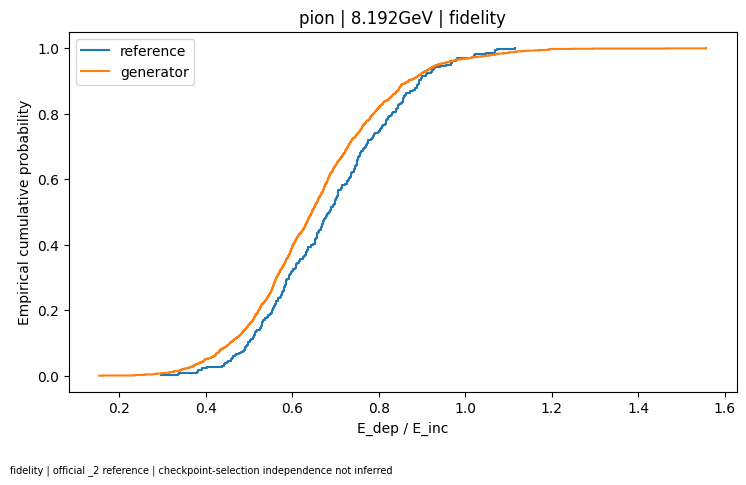

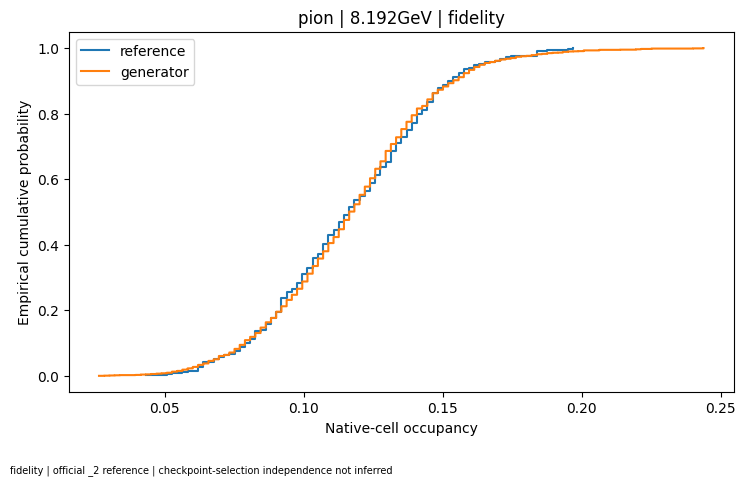

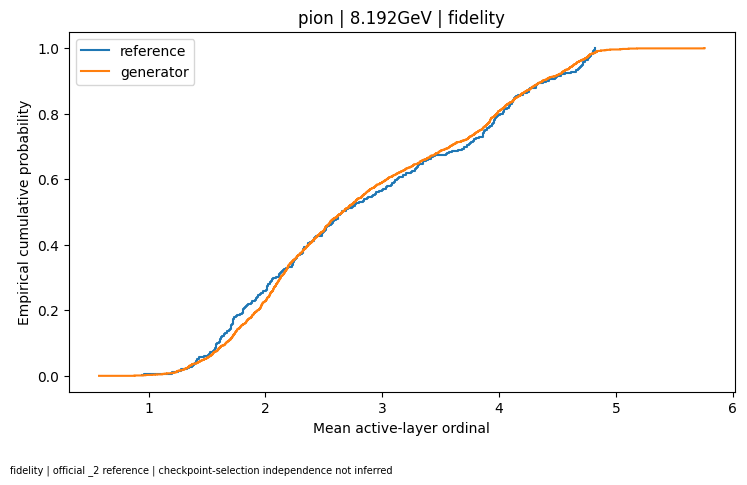

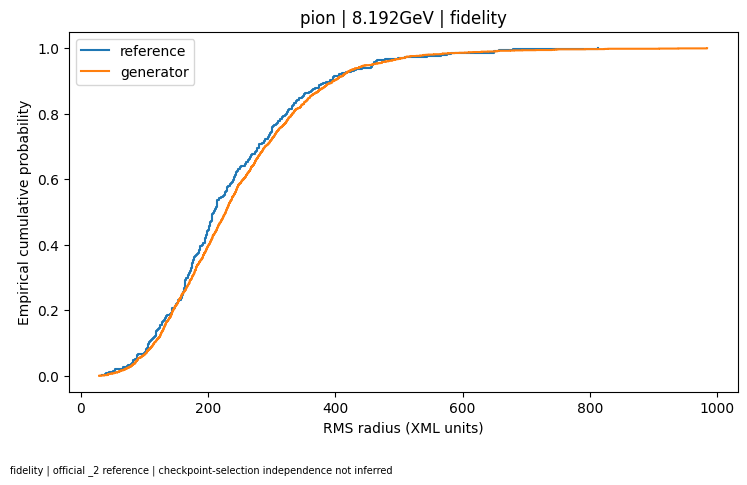

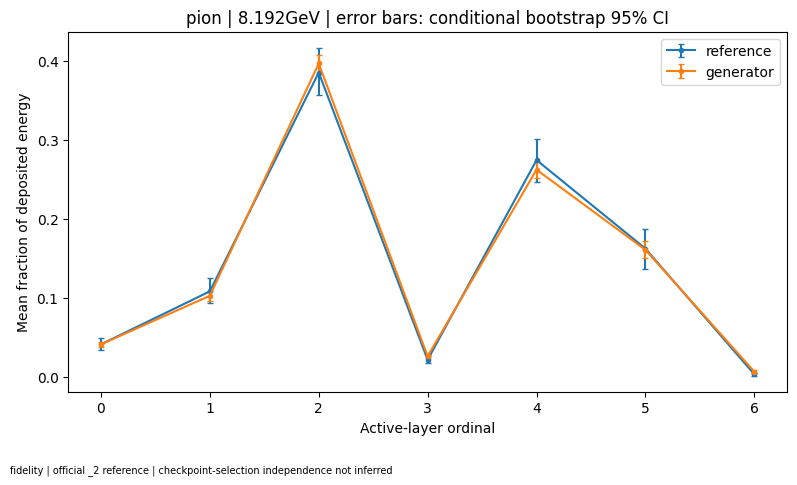

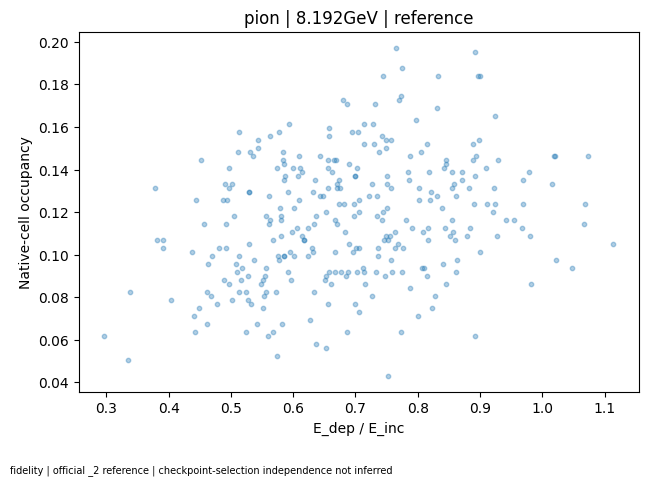

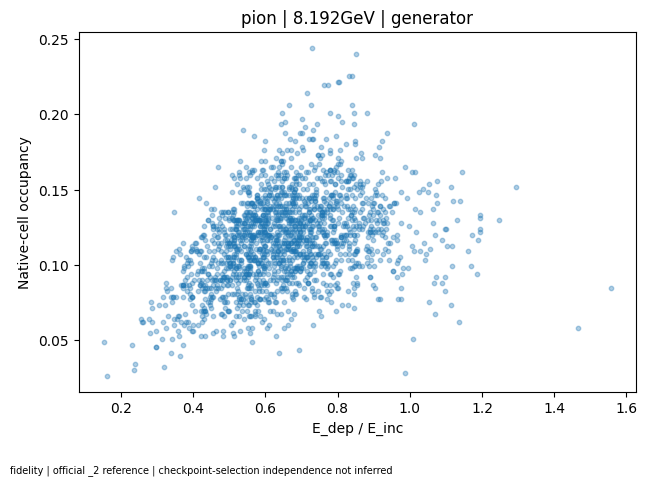

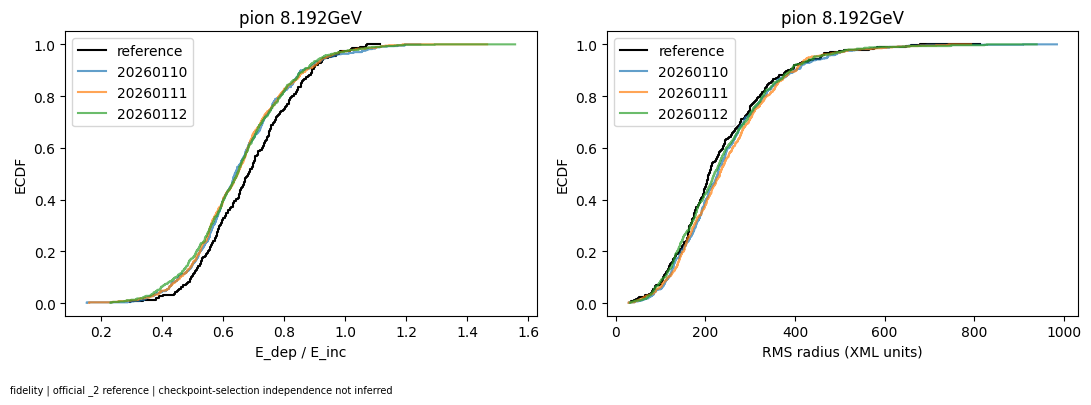

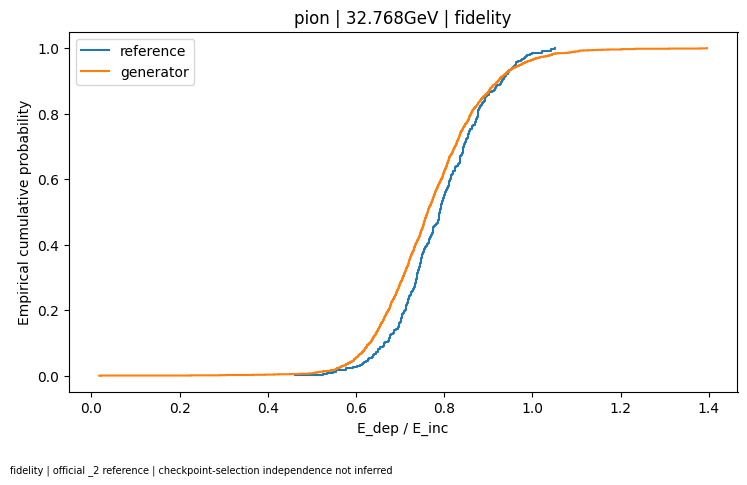

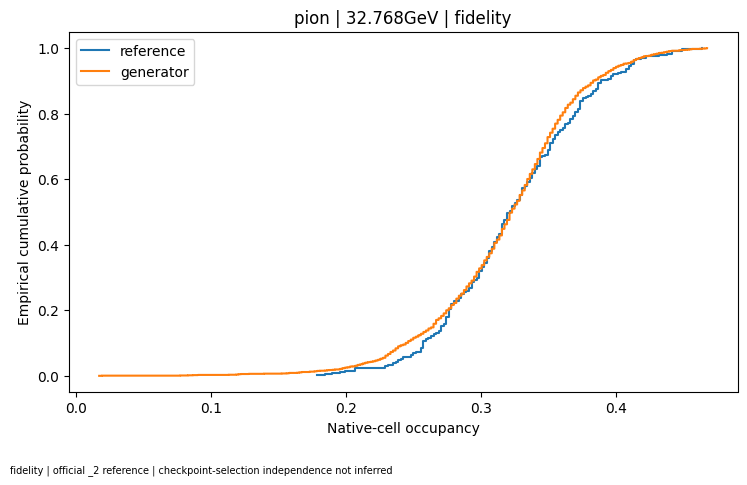

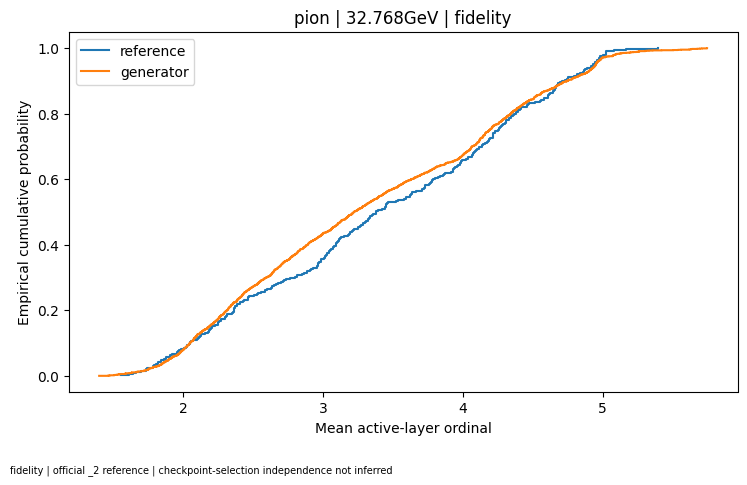

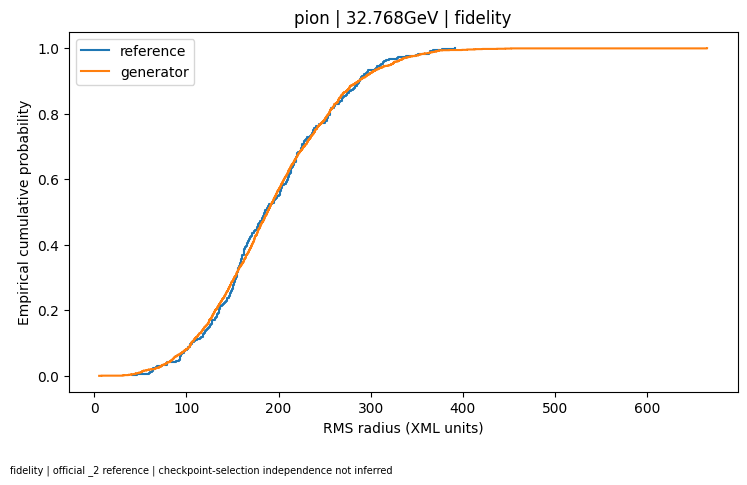

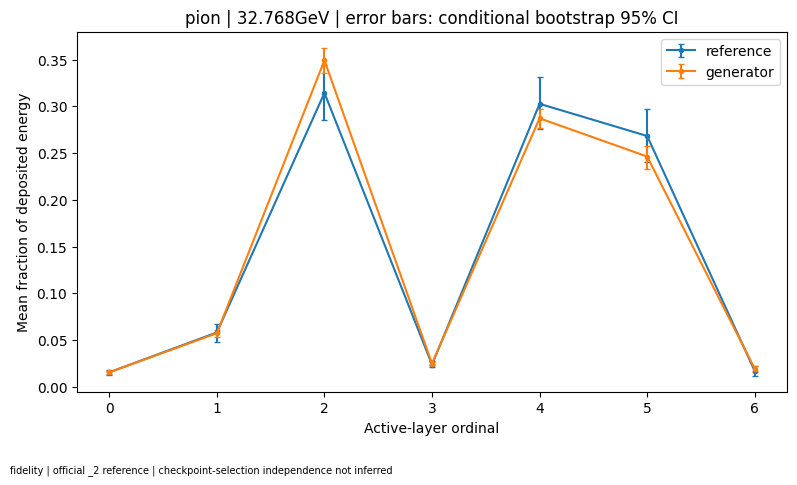

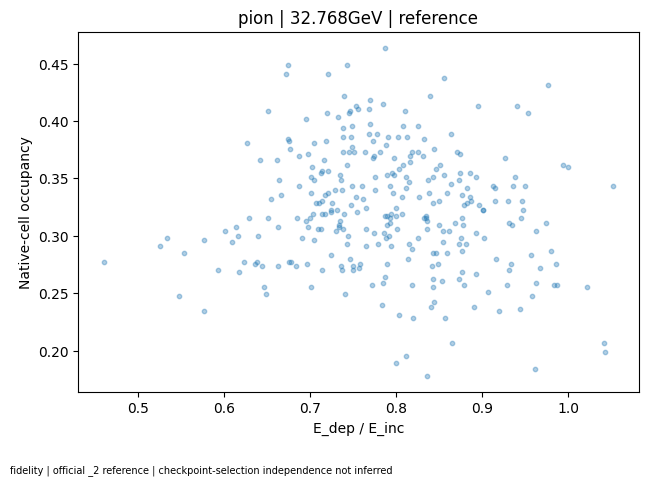

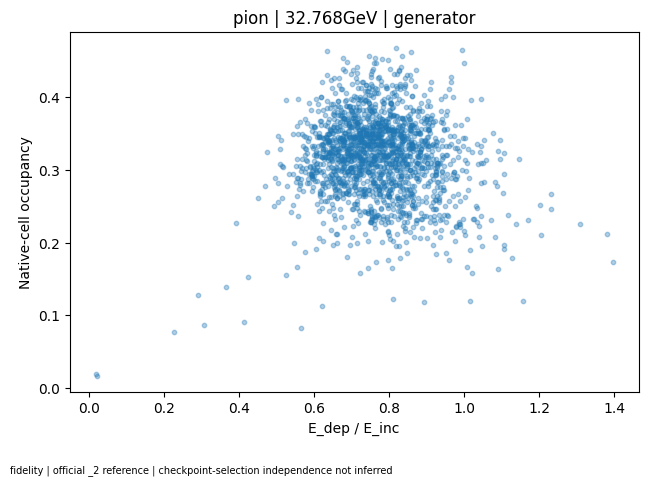

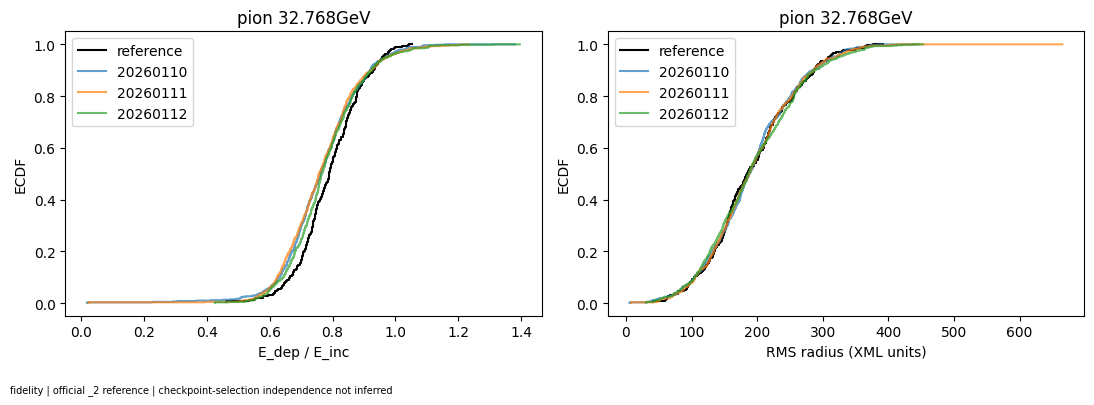

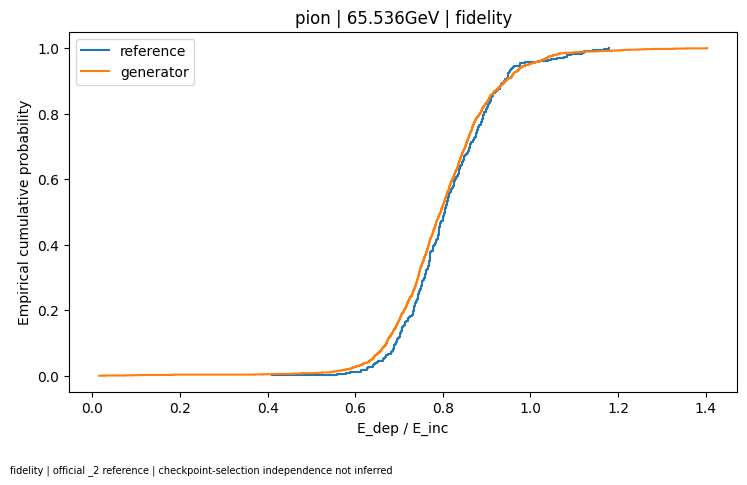

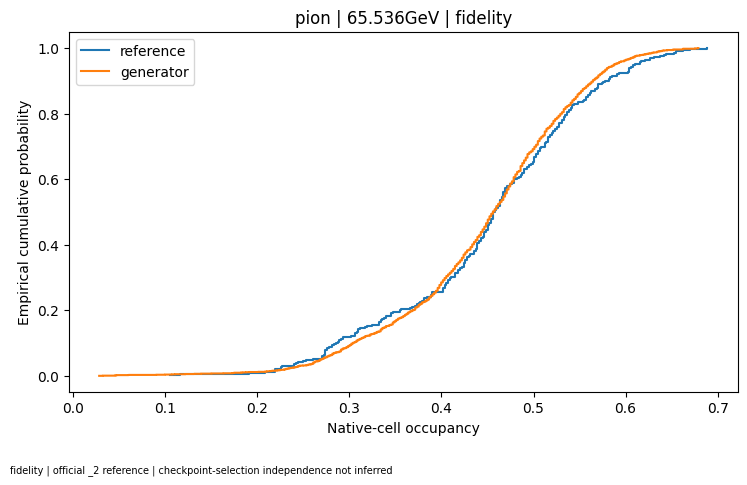

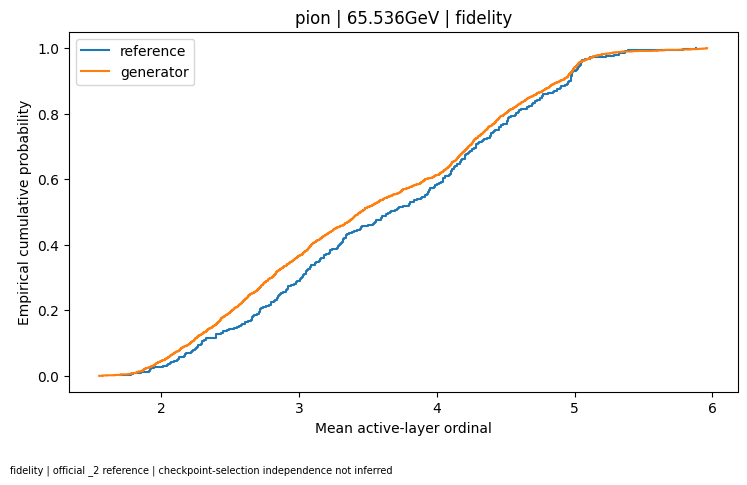

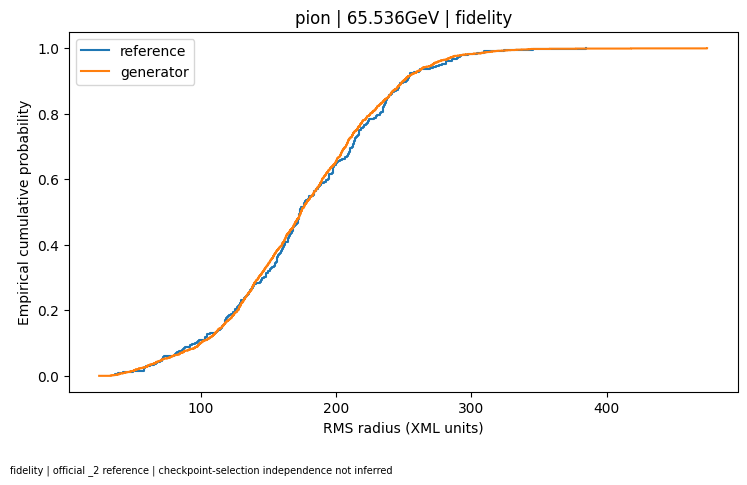

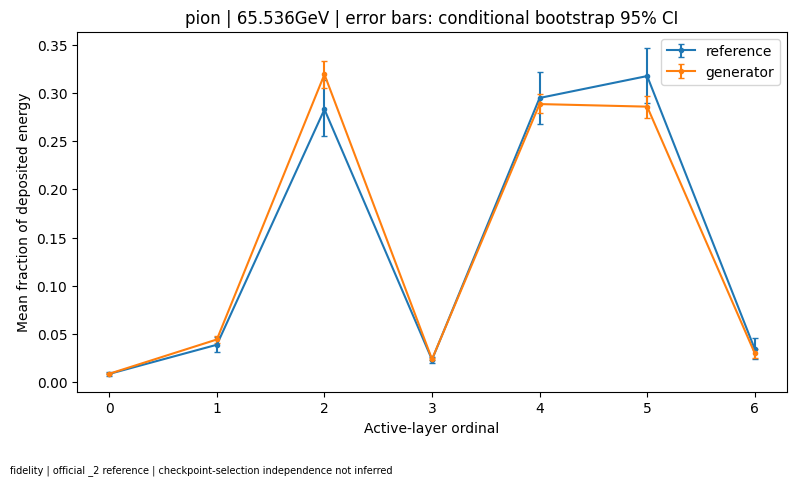

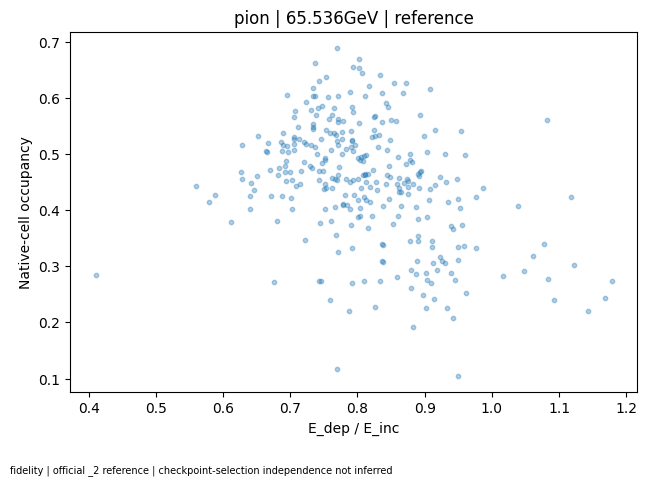

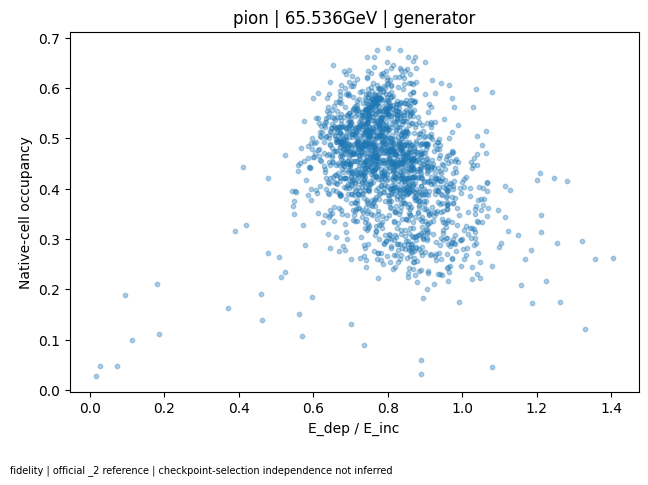

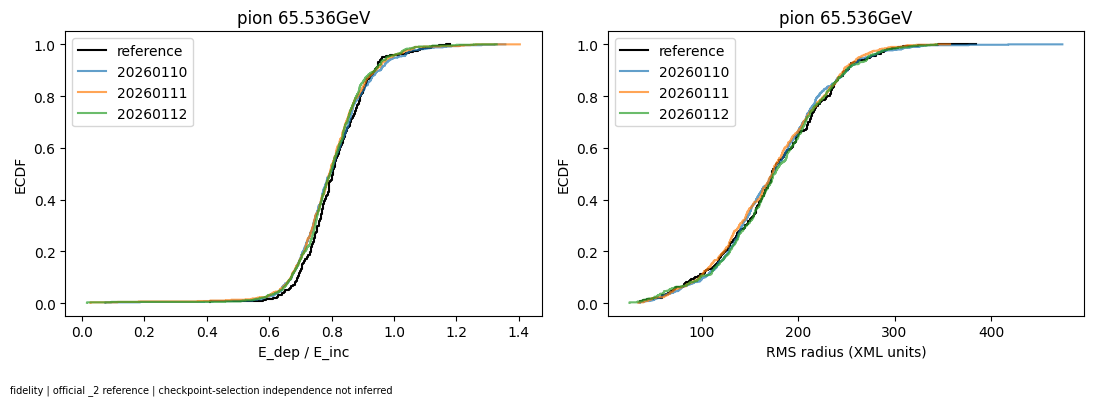

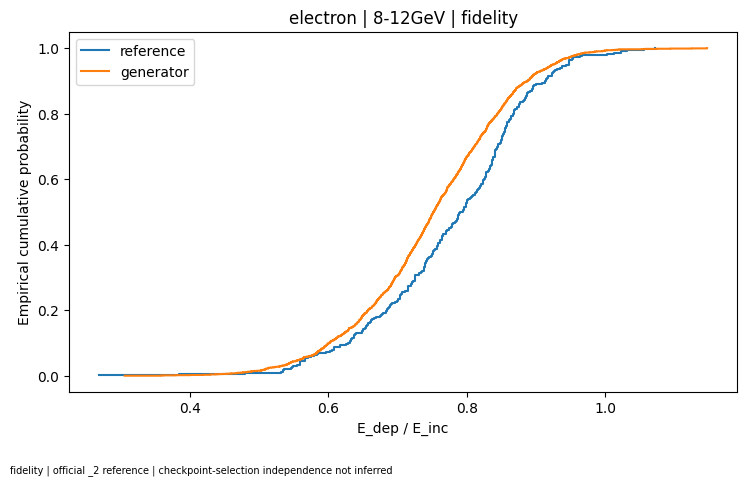

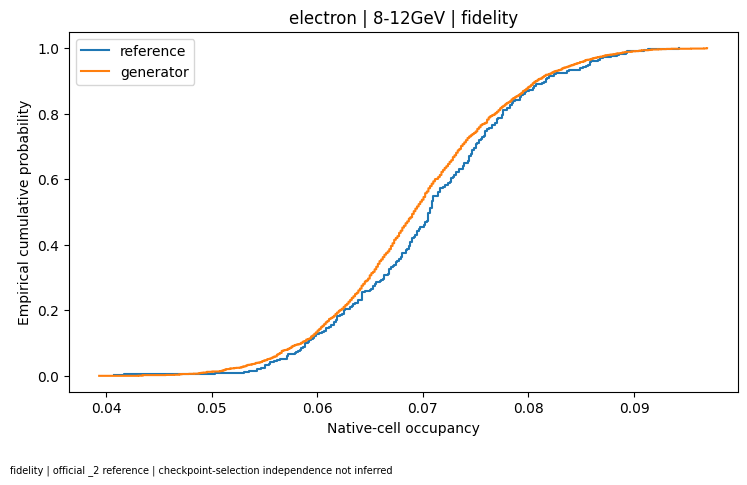

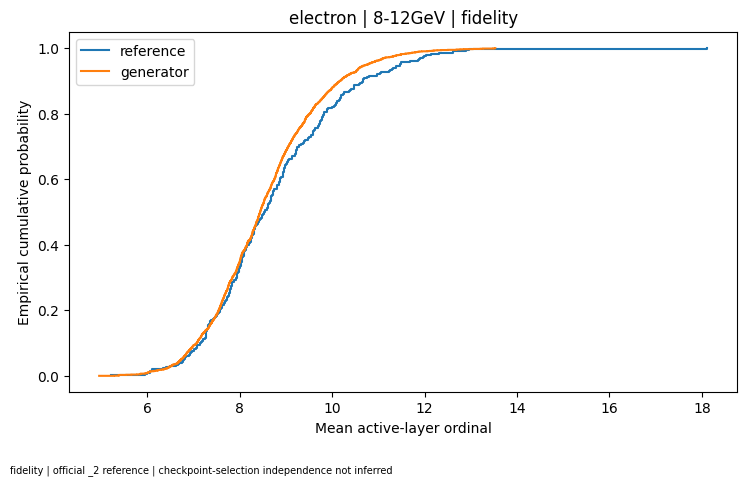

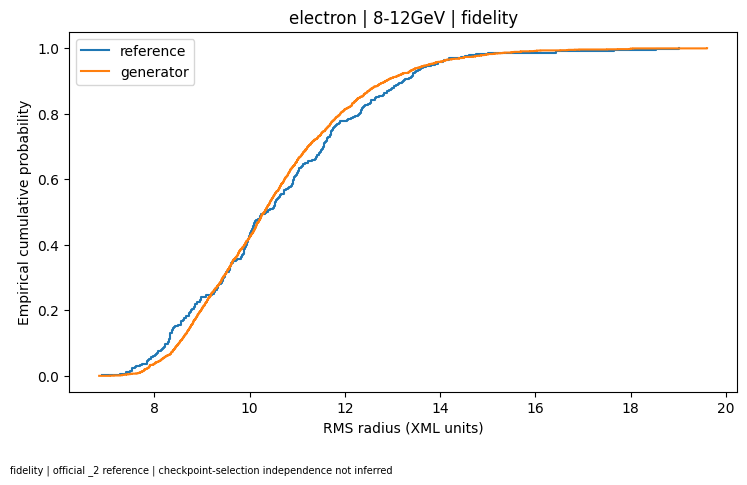

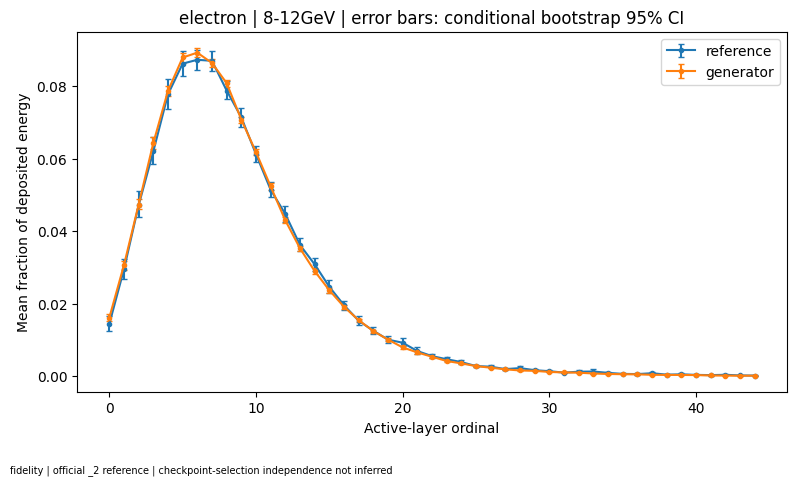

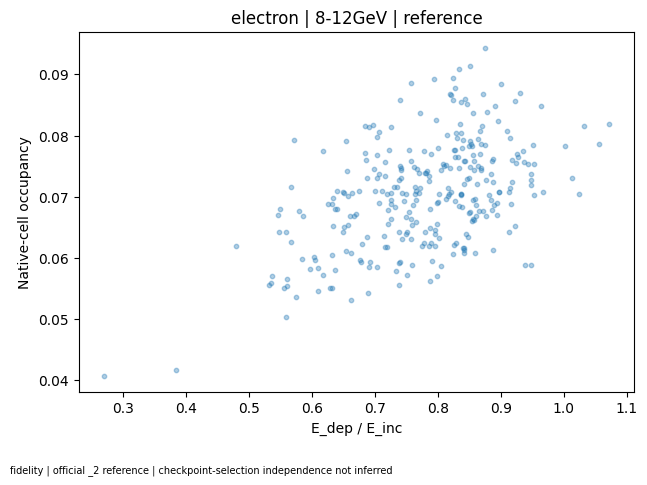

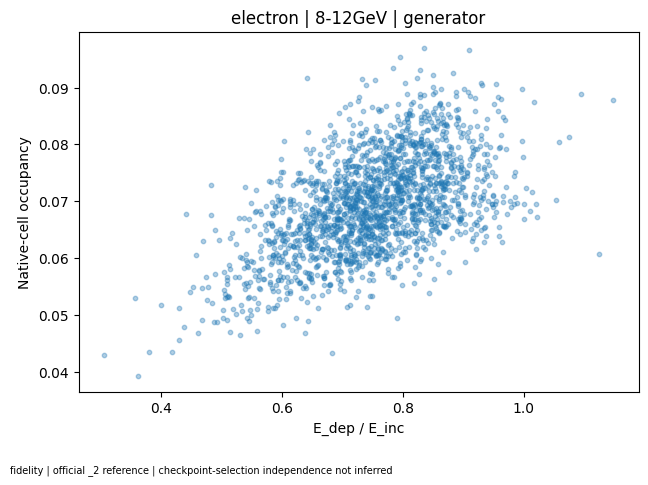

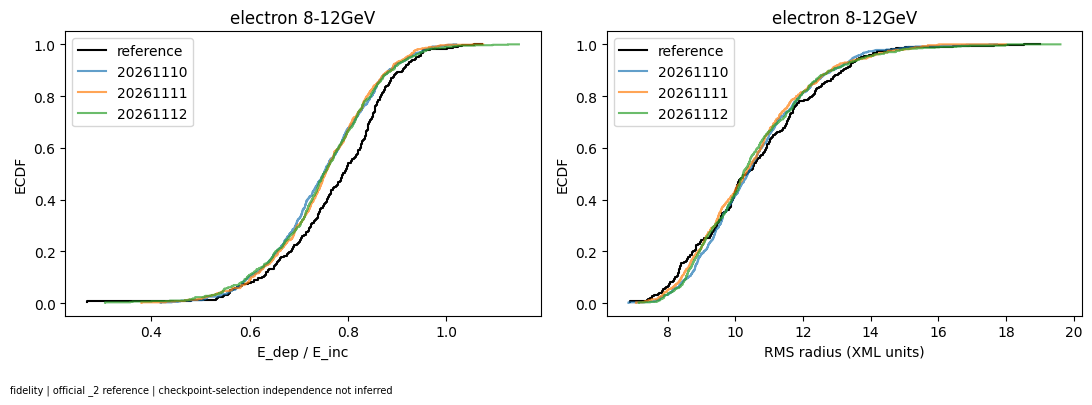

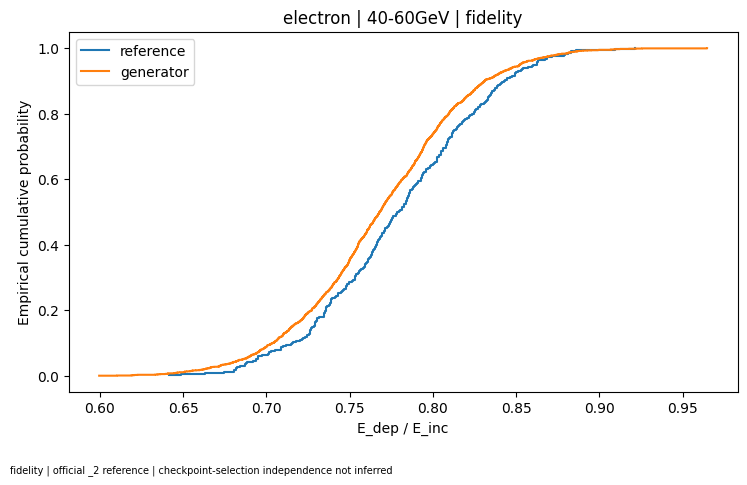

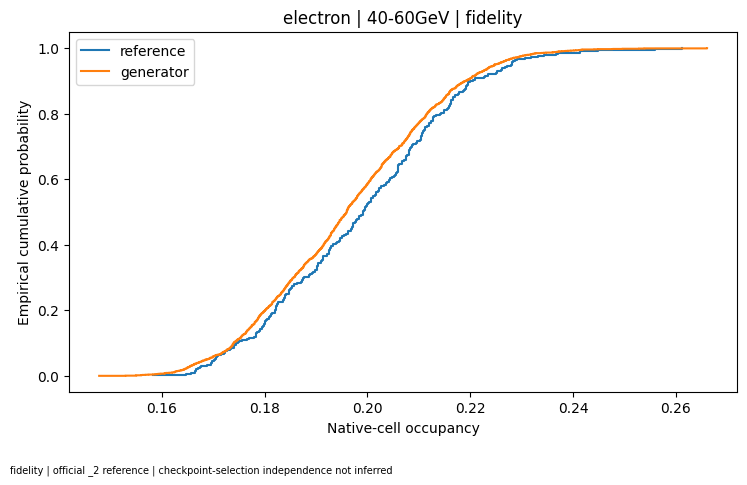

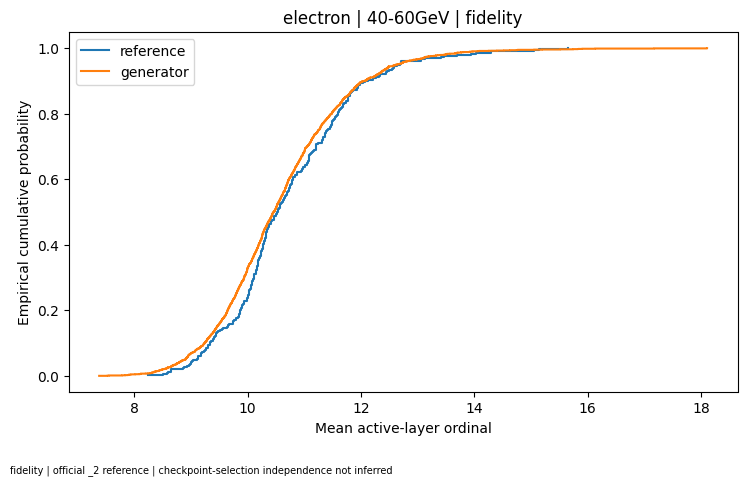

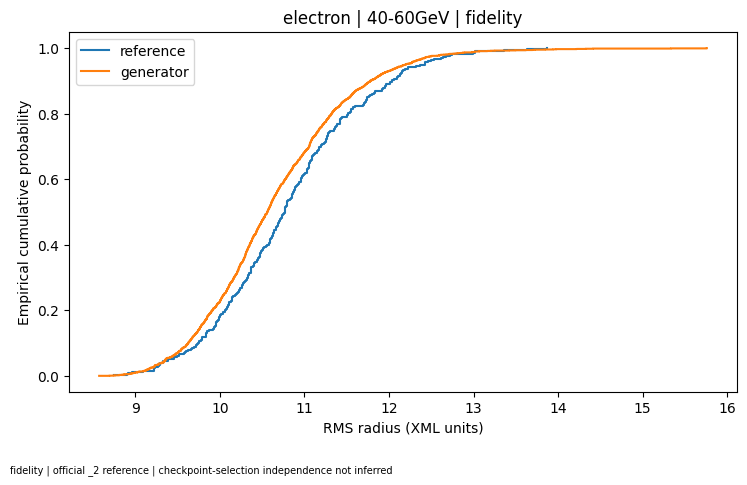

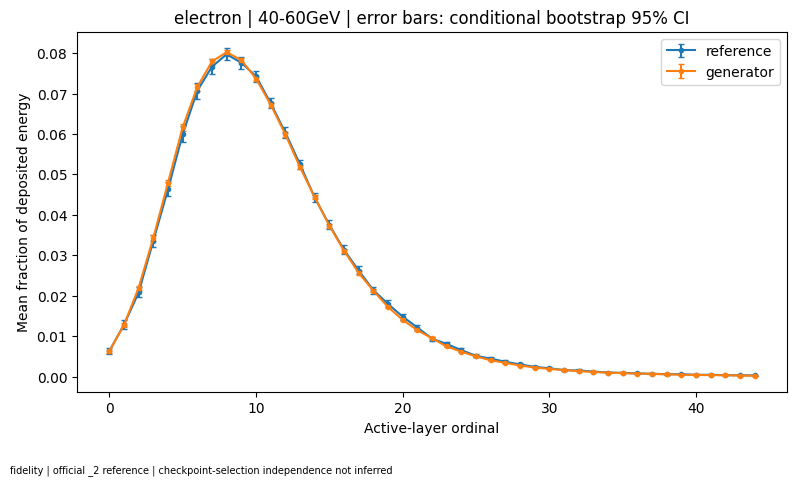

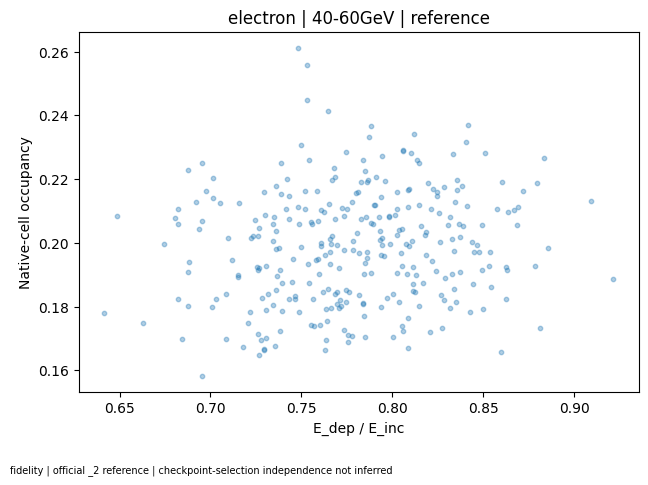

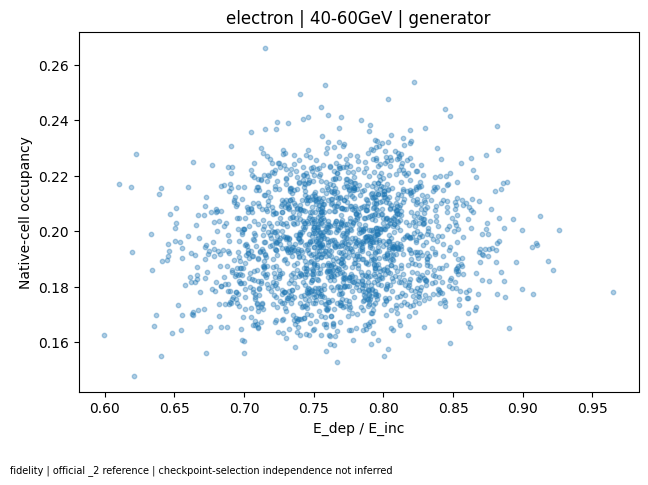

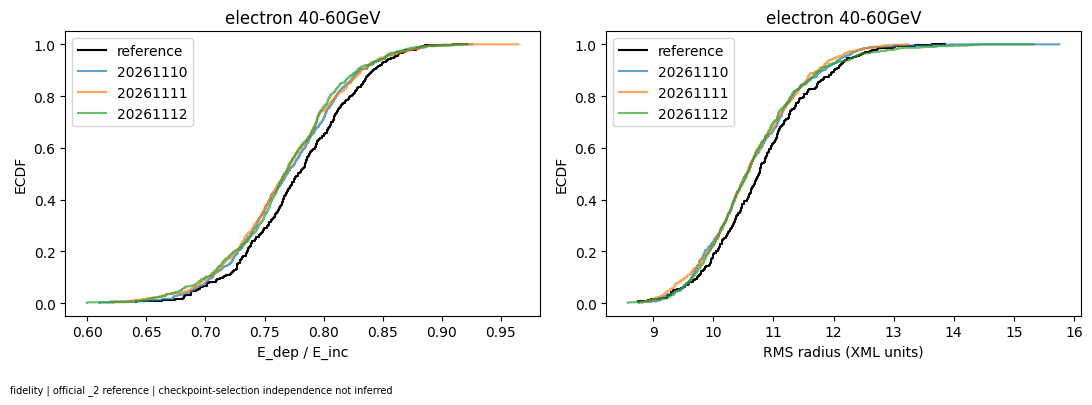

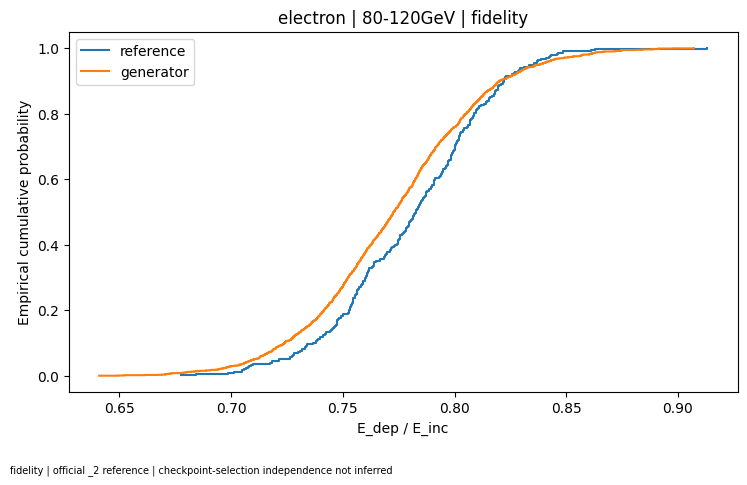

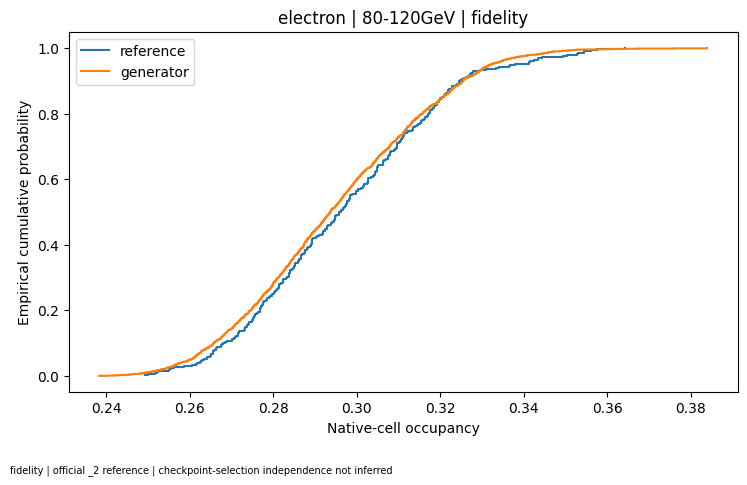

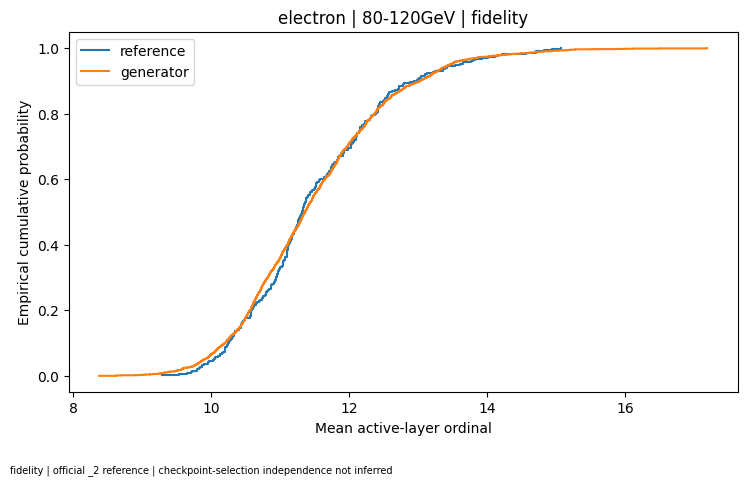

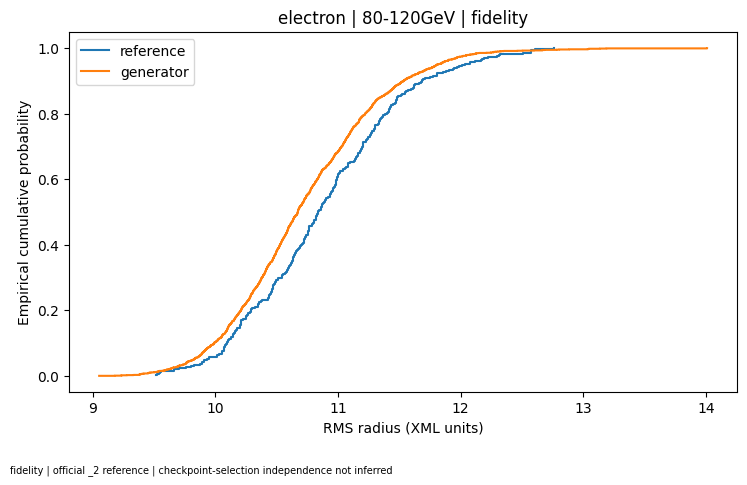

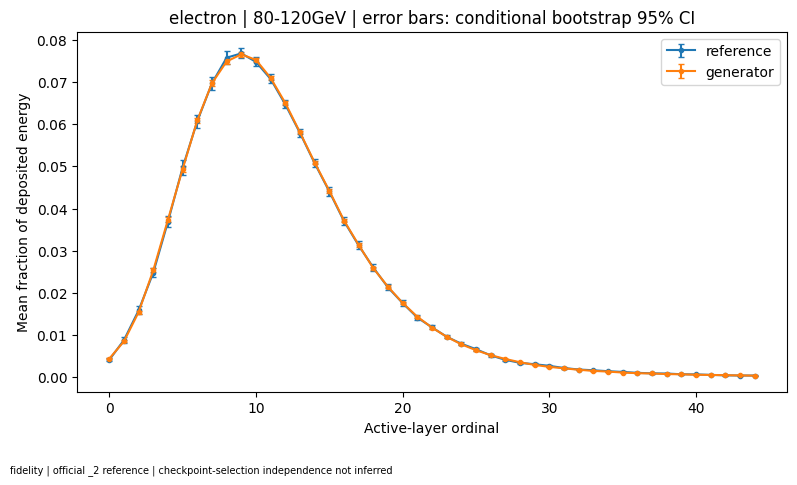

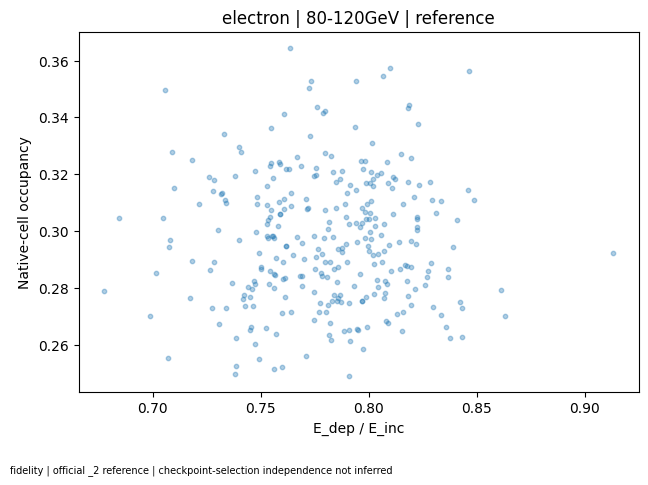

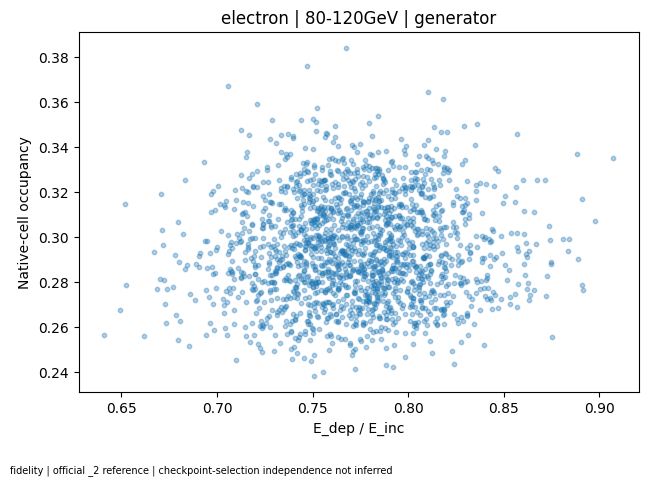

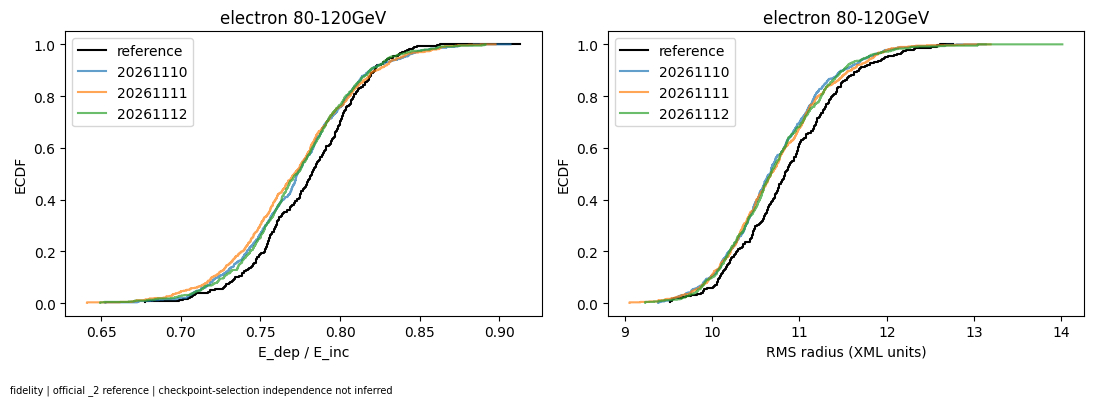

In [ ]:
MODE=PROFILE

def finish_figure(name):
    plt.gcf().text(.01,.005,f'{PROFILE} | official _2 reference | checkpoint-selection independence not inferred',fontsize=7)
    plt.tight_layout(rect=(0,.05,1,1))
    plt.savefig(OUT/'figures'/f'{name}.png',dpi=160,bbox_inches='tight')
    plt.show();plt.close()
def plot_fidelity(particle,label,columns=('response','occupancy','depth_layer','r_rms')):
    methods=Fidelity[particle][label]
    for col in columns:
        fig,ax=plt.subplots(figsize=(7.5,4.8))
        for method,df in methods.items():
            a=np.sort(finite_values(df[col]))
            if len(a): ax.step(a,np.arange(1,len(a)+1)/len(a),where='post',label=method)
        ax.set(xlabel=LABELS.get(col,col),ylabel='Empirical cumulative probability',
               title=f'{particle} | {label} | {MODE}')
        ax.legend(); finish_figure(f'{particle}_{label}_{col}_ecdf')
    frac_cols=[f'layer_fraction_{j}' for j in range(GEOMETRY[particle].n_layers)]
    fig,ax=plt.subplots(figsize=(8,4.8))
    for method,df in methods.items():
        a=df[frac_cols].to_numpy(); good=np.isfinite(a).all(axis=1); a=a[good]
        if not len(a): continue
        mean=a.mean(axis=0);clean=df.loc[good].reset_index(drop=True)
        rng=np.random.default_rng(named_seed('layer_ci',particle,label,method))
        draws=np.array([a[resample_rows(clean,rng)].mean(axis=0) for _ in range(CFG.n_bootstrap)])
        lo,hi=np.quantile(draws,[.025,.975],axis=0)
        ax.errorbar(np.arange(a.shape[1]),mean,yerr=np.maximum(np.vstack([mean-lo,hi-mean]),0),label=method,marker='.',capsize=2)
    ax.set(xlabel='Active-layer ordinal',ylabel='Mean fraction of deposited energy',
           title=f'{particle} | {label} | error bars: conditional bootstrap 95% CI')
    ax.legend(); finish_figure(f'{particle}_{label}_layer_fractions')
    for method in ('reference','generator'):
        df=methods[method]
        fig,ax=plt.subplots(figsize=(6.5,4.8))
        ax.scatter(df['response'],df['occupancy'],s=10,alpha=.35)
        ax.set(xlabel=LABELS['response'],ylabel=LABELS['occupancy'],title=f'{particle} | {label} | {method}')
        finish_figure(f'{particle}_{label}_{method}_response_vs_occupancy')
for p in PARTICLES:
    for s in STRATA[p]:
        plot_fidelity(p,s.label)
        fig,axes=plt.subplots(1,2,figsize=(11,4))
        methods=Fidelity[p][s.label]
        for ax,col in zip(axes,['response','r_rms']):
            a=np.sort(finite_values(methods['reference'][col]))
            if len(a): ax.step(a,np.arange(1,len(a)+1)/len(a),label='reference',color='black')
            for seed,g in methods['generator'].groupby('generation_seed'):
                a=np.sort(finite_values(g[col]))
                if len(a): ax.step(a,np.arange(1,len(a)+1)/len(a),label=str(seed),alpha=.7)
            ax.set(xlabel=LABELS[col],ylabel='ECDF',title=f'{p} {s.label}');ax.legend()
        finish_figure(f'{p}_{s.label}_seed_comparison')


## 12. Native HDF5 exports, report, and archive
Exports keep the **full stored native deposits before the common analysis cut** (generator values already include the original model ECUT). Units are converted back to MeV. Each seed/repeat gets a separate HDF5 and companion event-ID CSV; this is a compatible data export, not an execution of the official CaloChallenge evaluation suite.

The ZIP includes per-event tables, native banks, final model-space batches, actual batch seeds, geometry, dataset/checkpoint/source hashes, package versions, gates, figures, and the frozen plan. It excludes the multi-GB input files and checkpoints, which are identified by hashes. Save this notebook alongside it. Future outlier studies can select a saved event, load its batch from `generation_event_index.csv`, and reproduce the same batch conditions without regenerating the whole study.


In [ ]:
bank_table=pd.DataFrame(BANK_INDEX)
for row in BANK_INDEX:
    with np.load(OUT/row['path'],allow_pickle=False) as z:
        native=z['native'];energy=z['energy'];ids=z['event_id'];targets=z['target_id']
    name=Path(row['path']).stem
    with h5py.File(OUT/'official_exports'/f'{name}.hdf5','w') as f:
        f.create_dataset('showers',data=native*1e3,compression='gzip')
        f.create_dataset('incident_energies',data=energy[:,None]*1e3,compression='gzip')
        f.attrs['unit']='MeV';f.attrs['run_id']=RUN_ID
        f.attrs['analysis_cut_applied']=False
        f.attrs['provenance']='official _2 reference' if row['method']=='reference' else 'pretrained CaloDiffusion generation'
    pd.DataFrame(dict(event_id=ids,target_id=targets)).to_csv(OUT/'official_exports'/f'{name}_ids.csv',index=False)
MANIFEST['completed_utc']=datetime.now(timezone.utc).isoformat()
MANIFEST['technical_gates_passed']=sum(g['passed'] for g in GATES)
MANIFEST['generation_events']=len(BATCH_INDEX)
MANIFEST['status']='fidelity outputs complete; interpretation required'
save_json(OUT/'manifest.json',MANIFEST)
report=[f'# CaloDiffusion new-reference fidelity: {RUN_ID}',
    f'Profile: {PROFILE}. Selected particles: {PARTICLES}.',
    'All reference files passed their published Zenodo MD5 checksum.',
    'Checkpoint-selection independence is not established by the filename alone.',
    f'Technical gates passed: {sum(g["passed"] for g in GATES)}/{len(GATES)}.',
    f'Reference events per stratum: {CFG.n_test}; generated repeats per seed: {CFG.generation_repeats}.',
    'Review fidelity_summary.csv, fidelity_distances.csv, fidelity_correlations.csv and fidelity_per_seed.csv.',
    'Technical gates are not physics acceptance tests. There is no automatic good/bad verdict.',
    'Keep this archive separate from the earlier training-exposed results.',
    'Next: compare response, occupancy, layer profiles and radial distributions; only then plan particle-specific outlier diagnostics.',
    'Do not tune on these results and still call a later repeat an untouched evaluation.',
    'Simple fitted controls are deferred until an explicitly separate training/calibration source is configured.']
(OUT/'README_results.md').write_text('\n\n'.join(report))
# Record integrity for future transfer/review. The checksum list excludes itself.
checks={str(f.relative_to(OUT)):digest_file(f) for f in OUT.rglob('*') if f.is_file() and f.name!='artifact_sha256.json'}
save_json(OUT/'artifact_sha256.json',checks)
ARCHIVE=Path(shutil.make_archive(str(OUT),'zip',root_dir=OUT.parent,base_dir=OUT.name))
print('Results:',OUT,'\nArchive:',ARCHIVE)
DOWNLOAD_ARCHIVE = not USE_GOOGLE_DRIVE
if DOWNLOAD_ARCHIVE:
    from google.colab import files
    files.download(str(ARCHIVE))


Results: /content/drive/MyDrive/CaloDiffusion_new_reference/eval2_e270d961f41a6597 
Archive: /content/drive/MyDrive/CaloDiffusion_new_reference/eval2_e270d961f41a6597.zip


## How to continue after this run
1. Run the fidelity profile for each particle with the same settings; separate one-particle runs are intentional and have separate run IDs. Reopening with identical settings reuses batches. A different GPU/software stack creates a new run to avoid mixing replay assumptions.
2. Inspect response/occupancy first, then layer fractions and radial distributions, and compare each seed with the pooled result. Check empty rates and tail uncertainty. A discrepancy does not automatically imply a software defect.
3. If unusual events persist, use the saved event index and native bank for a dedicated electron, photon, or pion notebook. Report post-hoc selections transparently. Preserve the full batch and environment for exact replay.
4. Before claiming checkpoint-independent generalization, document training and model-selection exposure for these released checkpoints. Do not retrain simply because the previous reference was exposed.
5. If you increase reference counts later, freeze a new plan. Three seeds do not compensate for a small reference tail sample.

### Sources and implementation boundaries
- [Your validation notebook](https://github.com/Vishal21501/gen-hep-notebooks/blob/1bf9faf58c133c2e38358fbf8e39f21a6021e967/capstone/calodiffusion/Validated_CaloDiffusion_Study_all-particles_colab_GitHub_Vishal.ipynb): geometry, inverse transformations, sampling/replay audits, observables, and fidelity statistics adapted here.
- [Pinned project](https://github.com/Vishal21501/gen-hep-notebooks/tree/1bf9faf58c133c2e38358fbf8e39f21a6021e967/capstone/calodiffusion): unchanged pretrained model implementation and weights.
- [CaloDiffusion paper](https://arxiv.org/abs/2308.03876).
- [Zenodo Dataset 2](https://zenodo.org/records/6366271) and [Dataset 1](https://zenodo.org/records/8099322): file roles and published MD5 checksums verified 17 November 2026.


